# Task 1: LSTM Classifier Trained From Scratch

In [1]:
!pip install datasets nltk -q

In [2]:
import numpy as np
import random
import copy
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from collections import Counter
from datasets import load_dataset
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import time
import matplotlib.pyplot as plt


RANDOM_SEED = 2026
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)

rng = np.random.default_rng(RANDOM_SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')


Device: cuda


---
## Step 1: Data Split (90/10 train/val from official train set)

In [3]:
dataset = load_dataset('ag_news')
print(dataset)
print(f"Train size: {len(dataset['train'])}, Test size: {len(dataset['test'])}")

LABEL_NAMES = dataset['train'].features['label'].names
NUM_CLASSES = len(LABEL_NAMES)
print(f"Labels: {LABEL_NAMES}")
print(f"\nExample: {dataset['train'][0]}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
Train size: 120000, Test size: 7600
Labels: ['World', 'Sports', 'Business', 'Sci/Tech']

Example: {'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [4]:
#90/10 split with fixed seed
split = dataset['train'].train_test_split(test_size=0.1, seed=RANDOM_SEED, stratify_by_column='label')
train_data = split['train']
val_data = split['test']
test_data = dataset['test']

print(f'Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}')

#verify the label distribution
for name, ds in [('Train', train_data), ('Val', val_data), ('Test', test_data)]:
    dist = Counter(ds['label'])
    total = sum(dist.values())
    print(f"{name}: {{{', '.join(f'{k}: {v/total:.2%}' for k,v in sorted(dist.items()))}}}")

Train: 108000, Val: 12000, Test: 7600
Train: {0: 25.00%, 1: 25.00%, 2: 25.00%, 3: 25.00%}
Val: {0: 25.00%, 1: 25.00%, 2: 25.00%, 3: 25.00%}
Test: {0: 25.00%, 1: 25.00%, 2: 25.00%, 3: 25.00%}


---
## Step 2: Word-Level Tokenization & Vocabulary

In [5]:
#nltk word_tokenize (word-level)

import nltk
nltk.download('punkt_tab', quiet=True)

def tokenize(text):
    #Word-level tokenizer using nltk.word_tokenize.
    #Handles lowercasing, splits punctuation as separate tokens,
    #and preserves meaningful symbols
    return [t.lower() for t in nltk.word_tokenize(text)]

sample = train_data[0]['text']
print(f"Original: {sample[:120]}...")
print(f"Tokens:   {tokenize(sample)[:15]}...")

Original: Fanning your way through. Nobody ever made an illusion towards the fact that Sean Fanning, founder of the popular music ...
Tokens:   ['fanning', 'your', 'way', 'through', '.', 'nobody', 'ever', 'made', 'an', 'illusion', 'towards', 'the', 'fact', 'that', 'sean']...


In [6]:
#build vocabulary from the training set only

MIN_FREQ = 3  #use only words with frequency >= 3

# Count word frequencies
word_counts = Counter()
for example in train_data:
    word_counts.update(tokenize(example['text']))

print(f'Total unique words: {len(word_counts)}')
print(f'Words with freq >= {MIN_FREQ}: {sum(1 for c in word_counts.values() if c >= MIN_FREQ)}')

#special tokens
PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'

#build word2idx: PAD=0, UNK=1, then frequent words sorted alphabetically
vocab_words = sorted([w for w, c in word_counts.items() if c >= MIN_FREQ])
word2idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for w in vocab_words:
    word2idx[w] = len(word2idx)

idx2word = {i: w for w, i in word2idx.items()}
VOCAB_SIZE = len(word2idx)
PAD_IDX = word2idx[PAD_TOKEN]
UNK_IDX = word2idx[UNK_TOKEN]

print(f'Vocabulary size (with special tokens): {VOCAB_SIZE}')
print(f'PAD idx: {PAD_IDX}, UNK idx: {UNK_IDX}')

Total unique words: 94973
Words with freq >= 3: 39284
Vocabulary size (with special tokens): 39286
PAD idx: 0, UNK idx: 1


In [7]:
#convert text to token IDs with truncation
MAX_SEQ_LEN = 128

def text_to_ids(text, max_len=MAX_SEQ_LEN):
    tokens = tokenize(text)
    tokens = tokens[:max_len]  #truncate
    ids = [word2idx.get(t, UNK_IDX) for t in tokens]
    if len(ids) == 0:
        ids = [UNK_IDX]
    return ids

sample_ids = text_to_ids(train_data[0]['text'])
print(f'Token IDs (first 15): {sample_ids[:15]}')
print(f'Decoded back: {[idx2word[i] for i in sample_ids[:15]]}')
print(f'Sequence length: {len(sample_ids)}')

Token IDs (first 15): [14057, 39120, 38079, 35309, 205, 24579, 13510, 21850, 4022, 18266, 35921, 35063, 13952, 35051, 31131]
Decoded back: ['fanning', 'your', 'way', 'through', '.', 'nobody', 'ever', 'made', 'an', 'illusion', 'towards', 'the', 'fact', 'that', 'sean']
Sequence length: 40


In [8]:
#some stats about sequence lengths
train_lengths = [len(tokenize(ex['text'])) for ex in train_data]
print(f'Sequence length stats (before truncation):')
print(f'  Mean: {np.mean(train_lengths):.1f}')
print(f'  Median: {np.median(train_lengths):.1f}')
print(f'  Max: {np.max(train_lengths)}')
print(f'  % truncated at {MAX_SEQ_LEN}: {100*np.mean(np.array(train_lengths) > MAX_SEQ_LEN):.1f}%')

Sequence length stats (before truncation):
  Mean: 44.0
  Median: 43.0
  Max: 249
  % truncated at 128: 0.2%


---
## Step 3: Padding & LSTM Input Handling (pack_padded_sequence)

In [9]:
#PyTorch Dataset

class AGNewsDataset(Dataset):
    def __init__(self, hf_dataset):
        self.data = []
        for ex in hf_dataset:
            ids = text_to_ids(ex['text'])
            self.data.append((ids, ex['label']))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ids, label = self.data[idx]
        return ids, label

train_dataset = AGNewsDataset(train_data)
val_dataset = AGNewsDataset(val_data)
test_dataset = AGNewsDataset(test_data)

print(f'Datasets created: train={len(train_dataset)}, val={len(val_dataset)}, test={len(test_dataset)}')

Datasets created: train=108000, val=12000, test=7600


In [10]:
#collate function: pads sequences to batch max length,records true lengths for pack_padded_sequence

def collate_fn(batch):
    """
    Args:
        batch: list of (token_ids_list, label)
    Returns:
        padded_ids: LongTensor [batch_size, max_len_in_batch]
        lengths:    LongTensor [batch_size]  (true lengths before padding)
        labels:     LongTensor [batch_size]
    """
    ids_list, labels = zip(*batch)

    # True lengths (before padding)
    lengths = torch.tensor([len(ids) for ids in ids_list], dtype=torch.long)

    # Pad to the max length in this batch
    max_len = lengths.max().item()
    padded = torch.full((len(ids_list), max_len), PAD_IDX, dtype=torch.long)
    for i, ids in enumerate(ids_list):
        padded[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)

    labels = torch.tensor(labels, dtype=torch.long)
    return padded, lengths, labels

In [11]:
#Dataloaders
BATCH_SIZE = 64

def seed_worker(worker_id):
    worker_seed = RANDOM_SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(RANDOM_SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, worker_init_fn=seed_worker, generator=g)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         collate_fn=collate_fn)

print(f'Batches: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}')

Batches: train=1688, val=188, test=119


In [12]:
#present shapes, padding, lengths

sample_padded, sample_lengths, sample_labels = next(iter(train_loader))
print(f'Padded IDs shape: {sample_padded.shape}')
print(f'Lengths shape:    {sample_lengths.shape}')
print(f'Labels shape:     {sample_labels.shape}')
print(f'\nLength stats in batch: min={sample_lengths.min()}, max={sample_lengths.max()}, mean={sample_lengths.float().mean():.1f}')

Padded IDs shape: torch.Size([64, 102])
Lengths shape:    torch.Size([64])
Labels shape:     torch.Size([64])

Length stats in batch: min=18, max=102, mean=43.1


---
## Step 4: Model Architecture

In [13]:
class LSTMClassifier(nn.Module):
    """
    LSTM text classifier with pack_padded_sequence.

    Pooling strategy: last-hidden-state (length-aware)
      1. We use pack_padded_sequence so the LSTM never processes PAD tokens.
      2. The final hidden state h_n from nn.LSTM already corresponds to
        the last REAL token for each sequence (not PAD).
      3. For bidirectional: we concatenate the forward and backward final
        hidden states to vector of size 2*d_hidden.
    """
    def __init__(self, vocab_size, d_emb, d_hidden, num_classes,
                 num_layers=1, dropout=0.2, bidirectional=True, pad_idx=0):
        super().__init__()

        self.d_hidden = d_hidden
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1

        #embedding: PAD index produces zero vectors
        self.embedding = nn.Embedding(vocab_size, d_emb, padding_idx=pad_idx)

        #LSTM
        self.lstm = nn.LSTM(
            input_size=d_emb,
            hidden_size=d_hidden,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional
        )

        #dropout before classifier
        self.dropout = nn.Dropout(dropout)

        #Classifier head
        classifier_input = d_hidden * self.num_directions
        self.fc = nn.Linear(classifier_input, num_classes)

    def forward(self, padded_ids, lengths):
        """
        Args:
            padded_ids: [batch_size, seq_len] padded token IDs
            lengths:    [batch_size] true lengths
        Returns:
            logits: [batch_size, num_classes]
        """
        batch_size = padded_ids.size(0)

        # Sort by length descending (required by pack_padded_sequence)
        sorted_lengths, sort_idx = lengths.sort(descending=True)
        sorted_ids = padded_ids[sort_idx]

        # Embed
        embedded = self.embedding(sorted_ids)  # [B, T, d_emb]

        # Pack, run LSTM, unpack
        packed = pack_padded_sequence(embedded, sorted_lengths.cpu(), batch_first=True)
        packed_out, (h_n, c_n) = self.lstm(packed)
        # h_n shape: [num_layers * num_directions, batch_size, d_hidden]

        # Extract final hidden state from the last layer
        if self.bidirectional:
            # h_n[-2] = forward last layer, h_n[-1] = backward last layer
            hidden = torch.cat([h_n[-2], h_n[-1]], dim=1)  # [B, 2*d_hidden]
        else:
            hidden = h_n[-1]  # [B, d_hidden]

        # Unsort to restore original batch order
        _, unsort_idx = sort_idx.sort()
        hidden = hidden[unsort_idx]

        # Classify
        hidden = self.dropout(hidden)
        logits = self.fc(hidden)  # [B, num_classes]
        return logits

In [14]:
#Hyperparameters
D_EMB      = 128
D_HIDDEN   = 256
NUM_LAYERS = 1
DROPOUT    = 0.2
BIDIRECTIONAL = True
LEARNING_RATE = 1e-3
NUM_EPOCHS    = 6
GRAD_CLIP     = 1.0
PATIENCE      = 3   #we added early-stopping patience for baseline model

model = LSTMClassifier(
    vocab_size   = VOCAB_SIZE,
    d_emb        = D_EMB,
    d_hidden     = D_HIDDEN,
    num_classes  = NUM_CLASSES,
    num_layers   = NUM_LAYERS,
    dropout      = DROPOUT,
    bidirectional= BIDIRECTIONAL,
    pad_idx      = PAD_IDX,
).to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'\nTotal parameters:     {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')


LSTMClassifier(
  (embedding): Embedding(39286, 128, padding_idx=0)
  (lstm): LSTM(128, 256, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=512, out_features=4, bias=True)
)

Total parameters:     5,821,188
Trainable parameters: 5,821,188


---
## Step 5: Training

In [15]:
#training & evaluation functions

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


def train_one_epoch(model, loader, optimizer, criterion, grad_clip):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for padded, lengths, labels in loader:
        padded = padded.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(padded, lengths)
        loss = criterion(logits, labels)
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)

        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for padded, lengths, labels in loader:
        padded = padded.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        logits = model(padded, lengths)
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return avg_loss, accuracy

In [16]:
#training loop is as follows: early stopping + ReduceLROnPlateau + best-checkpoint saving

#LR scheduler: halves LR when val_loss hasn't improved for 1 epoch
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=1
)

history = {
    'train_loss': [], 'val_loss':  [],
    'train_acc':  [], 'val_acc':   [],
    'epoch_time': []
}

best_val_loss    = float('inf')
best_model_state = None
patience_counter = 0

print(f'Training BiLSTM for up to {NUM_EPOCHS} epochs '
      f'(early-stopping patience={PATIENCE}, ReduceLROnPlateau scheduler)')
sep = '-' * 76
print(f'{"Epoch":>5} {"Train Loss":>11} {"Val Loss":>11} '
      f'{"Train Acc":>10} {"Val Acc":>10} {"Time(s)":>8}  {"":>14}')
print(sep)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, GRAD_CLIP)
    val_loss,   val_acc   = evaluate(model, val_loader, criterion)
    elapsed = time.time() - t0

    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['epoch_time'].append(elapsed)

    # ── checkpoint / patience ──────────────────────────────────────────
    if val_loss < best_val_loss:
        best_val_loss    = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
        marker = '[best]'
    else:
        patience_counter += 1
        marker = f'patience {patience_counter}/{PATIENCE}'

    print(f'{epoch:5d} {train_loss:11.4f} {val_loss:11.4f} '
          f'{train_acc:10.4f} {val_acc:10.4f} {elapsed:8.1f}  {marker}')

    if patience_counter >= PATIENCE:
        print(f'\nEarly stopping triggered at epoch {epoch}.')
        break

# Restore best weights before any evaluation
model.load_state_dict(best_model_state)
best_epoch = history['val_loss'].index(min(history['val_loss'])) + 1
print(f'\nRestored best model from epoch {best_epoch}  (val_loss={best_val_loss:.4f})')
print(f'Best val accuracy  : {max(history["val_acc"]):.4f}')
print(f'Total training time: {sum(history["epoch_time"]):.1f}s')


Training BiLSTM for up to 6 epochs (early-stopping patience=3, ReduceLROnPlateau scheduler)
Epoch  Train Loss    Val Loss  Train Acc    Val Acc  Time(s)                
----------------------------------------------------------------------------
    1      0.4627      0.3130     0.8293     0.8878     29.3  [best]
    2      0.2288      0.2532     0.9223     0.9133     27.3  [best]
    3      0.1530      0.2513     0.9483     0.9166     27.2  [best]
    4      0.0969      0.2731     0.9668     0.9155     29.3  patience 1/3
    5      0.0578      0.3138     0.9802     0.9165     26.8  patience 2/3
    6      0.0236      0.3650     0.9926     0.9175     30.1  patience 3/3

Early stopping triggered at epoch 6.

Restored best model from epoch 3  (val_loss=0.2513)
Best val accuracy  : 0.9175
Total training time: 170.0s


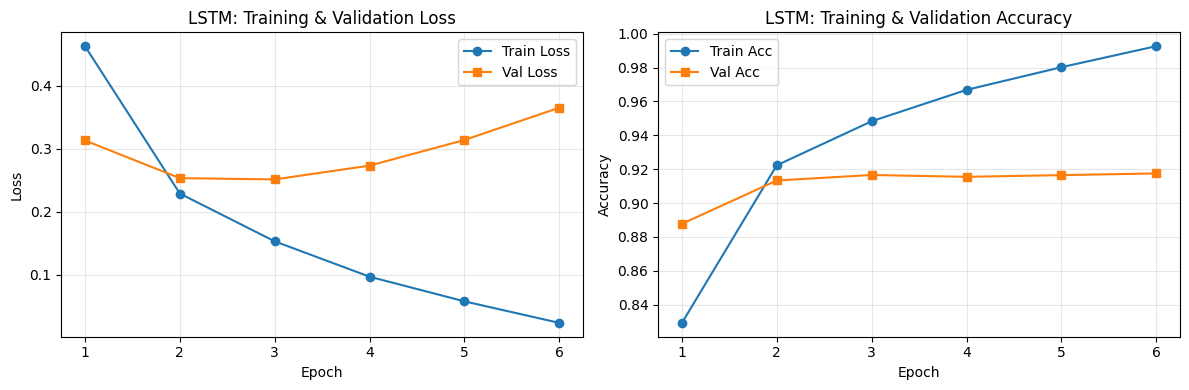

Saved: lstm_learning_curves.png


In [17]:
#Display of  Learning curves

epochs_range = range(1, NUM_EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Display of Loss curves
axes[0].plot(epochs_range, history['train_loss'], 'o-', label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'], 's-', label='Val Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('LSTM: Training & Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

#Display of Accuracy curves
axes[1].plot(epochs_range, history['train_acc'], 'o-', label='Train Acc')
axes[1].plot(epochs_range, history['val_acc'], 's-', label='Val Acc')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('LSTM: Training & Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('lstm_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: lstm_learning_curves.png')

---
## Step 6: Test Evaluation & Error Analysis

In [18]:
#test accuracy

test_loss, test_acc = evaluate(model, test_loader, criterion)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')

Test Loss: 0.2558
Test Accuracy: 0.9139 (91.39%)


In [19]:
#collects all predictions on test set

@torch.no_grad()
def get_predictions(model, loader):
    """Get all predictions and labels from a loader."""
    model.eval()
    all_preds = []
    all_labels = []
    for padded, lengths, labels in loader:
        padded = padded.to(device)
        lengths = lengths.to(device)
        logits = model(padded, lengths)
        preds = logits.argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(labels)
    return torch.cat(all_preds), torch.cat(all_labels)

test_preds, test_labels = get_predictions(model, test_loader)

#finds misclassified indices
misclassified_mask = test_preds != test_labels
misclassified_indices = misclassified_mask.nonzero(as_tuple=True)[0].tolist()
print(f'Total misclassified: {len(misclassified_indices)} / {len(test_labels)} ({100*len(misclassified_indices)/len(test_labels):.2f}%)')

Total misclassified: 654 / 7600 (8.61%)


In [20]:
#displaying 10 misclassified examples

NUM_EXAMPLES = 10
random.seed(RANDOM_SEED)
sample_misclassified = random.sample(misclassified_indices, min(NUM_EXAMPLES, len(misclassified_indices)))

print(f'{"="*80}')
print(f'MISCLASSIFIED EXAMPLES ({NUM_EXAMPLES} random samples)')
print(f'{"="*80}')

for i, idx in enumerate(sample_misclassified, 1):
    text = test_data[idx]['text']
    true_label = LABEL_NAMES[test_labels[idx].item()]
    pred_label = LABEL_NAMES[test_preds[idx].item()]

    #showing first 200 chars of text
    display_text = text[:200] + ('...' if len(text) > 200 else '')

    print(f'\n--- Example {i} (test index {idx}) ---')
    print(f'Text:      {display_text}')
    print(f'True:      {true_label}')
    print(f'Predicted: {pred_label}')

MISCLASSIFIED EXAMPLES (10 random samples)

--- Example 1 (test index 1210) ---
Text:      British industry at best in 10 years Manufacturing industry is enjoying its strongest performance for almost 10 years, according to a survey by the Engineering Employers Federation.
True:      Business
Predicted: Sci/Tech

--- Example 2 (test index 3582) ---
Text:      Nobel Economics Prize Awarded Norwegian-born Finn Kydland and Edward Prescott of the United States won the 2004 Nobel\economics prize, the Royal Swedish Academy of Sciences said on Monday.
True:      Business
Predicted: Sci/Tech

--- Example 3 (test index 5886) ---
Text:      Producer Price Surge Fuels Inflation Fears Producer prices surged 1.7 percent in October, their sharpest monthly increase in nearly 15 years.
True:      World
Predicted: Business

--- Example 4 (test index 6024) ---
Text:      Leading Indicators Down for 5th Month (Reuters) Reuters - A key forecasting gauge of future\U.S. economic activity fell for a fifth str

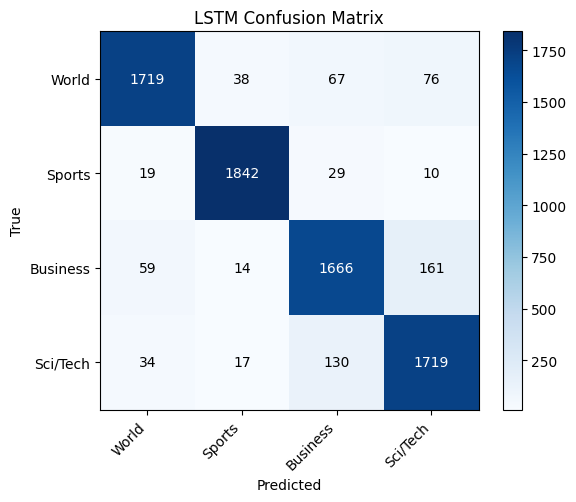


Classification Report:
              precision    recall  f1-score   support

       World       0.94      0.90      0.92      1900
      Sports       0.96      0.97      0.97      1900
    Business       0.88      0.88      0.88      1900
    Sci/Tech       0.87      0.90      0.89      1900

    accuracy                           0.91      7600
   macro avg       0.91      0.91      0.91      7600
weighted avg       0.91      0.91      0.91      7600



In [21]:
# Confusion matrix & classification report

from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(test_labels.numpy(), test_preds.numpy())

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
ax.set_title('LSTM Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
tick_marks = range(NUM_CLASSES)
ax.set_xticks(tick_marks)
ax.set_xticklabels(LABEL_NAMES, rotation=45, ha='right')
ax.set_yticks(tick_marks)
ax.set_yticklabels(LABEL_NAMES)

# Annotate cells
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', color=color, fontsize=10)

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('lstm_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nClassification Report:')
print(classification_report(test_labels.numpy(), test_preds.numpy(), target_names=LABEL_NAMES))

In [22]:
#Final summary
print('=' * 60)
print('TASK 1 SUMMARY: LSTM Classifier')
print('=' * 60)
print(f'Dataset: AG News (4-class)')
print(f'Train/Val/Test: {len(train_data)}/{len(val_data)}/{len(test_data)}')
print(f'Vocab size: {VOCAB_SIZE} (min_freq={MIN_FREQ})')
print(f'Max seq len: {MAX_SEQ_LEN}')
print(f'\nModel: {"BiLSTM" if BIDIRECTIONAL else "LSTM"}')
print(f'  Embedding dim: {D_EMB}')
print(f'  Hidden size: {D_HIDDEN}')
print(f'  Layers: {NUM_LAYERS}')
print(f'  Dropout: {DROPOUT}')
print(f'  Pooling: last hidden state (length-aware via pack_padded_sequence)')
print(f'  Total params: {total_params:,}')
print(f'\nTraining:')
print(f'  Optimizer: Adam (lr={LEARNING_RATE})')
print(f'  Gradient clipping: {GRAD_CLIP}')
print(f'  Batch size: {BATCH_SIZE}')
print(f'  Epochs: {NUM_EPOCHS}')
print(f'  Avg time/epoch: {np.mean(history["epoch_time"]):.1f}s')
print(f'  Total time: {sum(history["epoch_time"]):.1f}s')
print(f'\nResults:')
print(f'  Best val accuracy: {max(history["val_acc"]):.4f} (epoch {np.argmax(history["val_acc"])+1})')
print(f'  Final val accuracy: {history["val_acc"][-1]:.4f}')
print(f'  Test accuracy: {test_acc:.4f}')
print(f'  Test loss: {test_loss:.4f}')

TASK 1 SUMMARY: LSTM Classifier
Dataset: AG News (4-class)
Train/Val/Test: 108000/12000/7600
Vocab size: 39286 (min_freq=3)
Max seq len: 128

Model: BiLSTM
  Embedding dim: 128
  Hidden size: 256
  Layers: 1
  Dropout: 0.2
  Pooling: last hidden state (length-aware via pack_padded_sequence)
  Total params: 5,821,188

Training:
  Optimizer: Adam (lr=0.001)
  Gradient clipping: 1.0
  Batch size: 64
  Epochs: 6
  Avg time/epoch: 28.3s
  Total time: 170.0s

Results:
  Best val accuracy: 0.9175 (epoch 6)
  Final val accuracy: 0.9175
  Test accuracy: 0.9139
  Test loss: 0.2558


---
## Going Beyond 1: Systematic Model Comparison

We run a **full ablation study** across all combinations of:
- **Architecture**: LSTM vs GRU
- **Directionality**: Unidirectional vs Bidirectional
- **Pooling strategy**: `last` (last real hidden state) · `mean` (masked mean) · `max` (masked max)

Every variant uses identical hyperparameters, optimiser, LR scheduler, and early-stopping,
so performance differences are attributable solely to model choice.

**7 configurations total:**

| # | Model | Direction | Pooling |
|---|-------|-----------|--------|
| 1 | LSTM | Uni | Last |
| 2 | LSTM | Uni | Mean |
| 3 | LSTM | Bi | Last |
| 4 | LSTM | Bi | Mean |
| 5 | LSTM | Bi | Max |
| 6 | GRU | Uni | Mean |
| 7 | GRU | Bi | Mean |


In [23]:
#flexible SequenceClassifier
#
# Pooling strategies explained:
#   'last': final hidden state at the last real token (length-aware via packing).
#             For Bi-RNNs we concatenate forward and backward final states: [B, 2H].
#   'mean': average hidden states over real positions only (PAD masked out).
#   'max': element-wise max over real positions (PAD positions filled with -inf
#             before max so they never win).

class SequenceClassifier(nn.Module):
    """
    Unified sequence classifier.
    arch      : 'lstm' or 'gru'
    pooling   : 'last'|'mean'|'max'
    bidirectional: True/False
    """
    def __init__(self, vocab_size, d_emb, d_hidden, num_classes,
                 num_layers=1, dropout=0.2,
                 arch='lstm', bidirectional=False, pooling='last',
                 pad_idx=0):
        super().__init__()
        assert arch    in ('lstm', 'gru'),         "arch must be 'lstm' or 'gru'"
        assert pooling in ('last', 'mean', 'max'), "pooling must be 'last', 'mean', or 'max'"

        self.arch          = arch
        self.pooling       = pooling
        self.bidirectional = bidirectional
        self.num_dirs      = 2 if bidirectional else 1

        self.embedding = nn.Embedding(vocab_size, d_emb, padding_idx=pad_idx)

        rnn_cls   = nn.LSTM if arch == 'lstm' else nn.GRU
        self.rnn  = rnn_cls(
            input_size    = d_emb,
            hidden_size   = d_hidden,
            num_layers    = num_layers,
            batch_first   = True,
            dropout       = dropout if num_layers > 1 else 0.0,
            bidirectional = bidirectional,
        )
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(d_hidden * self.num_dirs, num_classes)

    def forward(self, padded_ids, lengths):
        # Sort by length descending (required by pack_padded_sequence)
        sorted_len, sort_idx = lengths.sort(descending=True)
        emb = self.embedding(padded_ids[sort_idx])       # [B, T, d_emb]

        packed     = pack_padded_sequence(emb, sorted_len.cpu(),
                                          batch_first=True, enforce_sorted=True)
        packed_out, hidden = self.rnn(packed)

        if self.pooling == 'last':
            # h_n: [num_layers*num_dirs, B, H]
            h_n = hidden[0] if self.arch == 'lstm' else hidden
            out = (torch.cat([h_n[-2], h_n[-1]], dim=1)
                   if self.bidirectional else h_n[-1])   # [B, H*dirs]

        else:  # 'mean' or 'max' — need all time steps
            rnn_out, _ = pad_packed_sequence(packed_out, batch_first=True)
            # rnn_out: [B, T', H*dirs]

            # Boolean mask: True for real tokens, False for PAD
            T    = rnn_out.size(1)
            mask = (torch.arange(T, device=rnn_out.device).unsqueeze(0)
                    < sorted_len.to(rnn_out.device).unsqueeze(1))  # [B, T']

            if self.pooling == 'mean':
                m   = mask.unsqueeze(2).float()            # [B, T', 1]
                out = ((rnn_out * m).sum(1)
                       / m.sum(1).clamp(min=1e-9))         # [B, H*dirs]
            else:  # 'max'
                inf_mask = ~mask.unsqueeze(2).expand_as(rnn_out)
                out = rnn_out.masked_fill(inf_mask, float('-inf')).max(dim=1).values

        # Unsort to restore original batch order
        _, unsort_idx = sort_idx.sort()
        out = self.drop(out[unsort_idx])
        return self.fc(out)

print('SequenceClassifier defined  ok')


SequenceClassifier defined  ok


In [24]:
#experiment harness
# Each call: fresh model, Adam + ReduceLROnPlateau, early stopping,
# best-checkpoint restore, then test evaluation.

EXP_PATIENCE = 2   # tighter patience for comparison (keeps Colab runtime manageable)

def run_experiment(cfg, embedding_weights=None, verbose=True):
    """
    Train a SequenceClassifier defined by cfg.
    cfg keys: name, arch, bidirectional, pooling
              + optional overrides: d_emb, d_hidden, num_layers, dropout, lr
    embedding_weights : FloatTensor [vocab_size, d_emb] to pre-load (GloVe).
    Returns a results dict.
    """
    SEP = '-' * 58
    if verbose:
        print(f'\n{SEP}')
        print(f'  {cfg["name"]}')
        print(f'  arch={cfg["arch"]}  bi={cfg["bidirectional"]}  pooling={cfg["pooling"]}  '
              f'd_emb={cfg.get("d_emb",D_EMB)}  d_hidden={cfg.get("d_hidden",D_HIDDEN)}')
        print(SEP)

    torch.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)

    mdl = SequenceClassifier(
        vocab_size    = VOCAB_SIZE,
        d_emb         = cfg.get('d_emb',     D_EMB),
        d_hidden      = cfg.get('d_hidden',  D_HIDDEN),
        num_classes   = NUM_CLASSES,
        num_layers    = cfg.get('num_layers',NUM_LAYERS),
        dropout       = cfg.get('dropout',   DROPOUT),
        arch          = cfg['arch'],
        bidirectional = cfg['bidirectional'],
        pooling       = cfg['pooling'],
        pad_idx       = PAD_IDX,
    ).to(device)

    if embedding_weights is not None:
        mdl.embedding.weight.data.copy_(embedding_weights)
        mdl.embedding.weight.requires_grad = True   # fine-tune embeddings

    n_params = sum(p.numel() for p in mdl.parameters() if p.requires_grad)

    opt   = torch.optim.Adam(mdl.parameters(), lr=cfg.get('lr', LEARNING_RATE))
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                opt, mode='min', factor=0.5, patience=1)
    crit  = nn.CrossEntropyLoss()

    hist     = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
    best_vl  = float('inf')
    best_st  = None
    pat_cnt  = 0

    ep_times = []

    for ep in range(1, NUM_EPOCHS + 1):
        t0       = time.time()
        tl, ta   = train_one_epoch(mdl, train_loader, opt, crit, GRAD_CLIP)
        vl, va   = evaluate(mdl, val_loader, crit)
        ep_time  = time.time() - t0
        sched.step(vl)

        hist['train_loss'].append(tl); hist['val_loss'].append(vl)
        hist['train_acc'].append(ta);  hist['val_acc'].append(va)
        ep_times.append(ep_time)

        if vl < best_vl:
            best_vl, best_st, pat_cnt = vl, copy.deepcopy(mdl.state_dict()), 0
            marker = '[best]'
        else:
            pat_cnt += 1
            marker = f'p{pat_cnt}/{EXP_PATIENCE}'

        if verbose:
            print(f'  ep {ep}  tl={tl:.4f}  vl={vl:.4f}  '
                  f'va={va:.4f}  {ep_time:.0f}s  {marker}')

        if pat_cnt >= EXP_PATIENCE:
            if verbose: print('  -> early stop')
            break

    mdl.load_state_dict(best_st)

    _, test_acc  = evaluate(mdl, test_loader, crit)
    preds, lbls  = get_predictions(mdl, test_loader)
    test_f1      = f1_score(lbls.numpy(), preds.numpy(), average='macro')

    return {
        'name':          cfg['name'],
        'arch':          cfg['arch'],
        'bidirectional': cfg['bidirectional'],
        'pooling':       cfg['pooling'],
        'n_params':      n_params,
        'best_val_acc':  max(hist['val_acc']),
        'best_val_loss': best_vl,
        'test_acc':      test_acc,
        'test_f1':       test_f1,
        'epochs':        len(hist['train_loss']),
        'history':       hist,
        'model':         mdl,
        'ep_times':      ep_times,
        'time_per_epoch': np.mean(ep_times),
    }

print('run_experiment() defined  ok')


run_experiment() defined  ok


In [25]:
#Ablation configurations
# All variants share: D_EMB=128, D_HIDDEN=256, NUM_LAYERS=1, DROPOUT=0.2, Adam lr=1e-3, batch=64, max_seq_len=128.

EXPERIMENT_CONFIGS = [
    # Unidirectional LSTM
    {'name': 'LSTM-Uni-Last', 'arch': 'lstm', 'bidirectional': False, 'pooling': 'last'},
    {'name': 'LSTM-Uni-Mean', 'arch': 'lstm', 'bidirectional': False, 'pooling': 'mean'},
    # Bidirectional LSTM
    {'name': 'LSTM-Bi-Last',  'arch': 'lstm', 'bidirectional': True,  'pooling': 'last'},
    {'name': 'LSTM-Bi-Mean',  'arch': 'lstm', 'bidirectional': True,  'pooling': 'mean'},
    {'name': 'LSTM-Bi-Max',   'arch': 'lstm', 'bidirectional': True,  'pooling': 'max'},
    # GRU (fewer parameters, often comparable performance)
    {'name': 'GRU-Uni-Mean',  'arch': 'gru',  'bidirectional': False, 'pooling': 'mean'},
    {'name': 'GRU-Bi-Mean',   'arch': 'gru',  'bidirectional': True,  'pooling': 'mean'},
]

all_results  = []
total_t0     = time.time()

for cfg in EXPERIMENT_CONFIGS:
    res = run_experiment(cfg)
    all_results.append(res)

total_min = (time.time() - total_t0) / 60
print(f'\nAll {len(all_results)} experiments finished in {total_min:.1f} min')



----------------------------------------------------------
  LSTM-Uni-Last
  arch=lstm  bi=False  pooling=last  d_emb=128  d_hidden=256
----------------------------------------------------------
  ep 1  tl=0.5247  vl=0.3142  va=0.8938  19s  [best]
  ep 2  tl=0.2593  vl=0.2650  va=0.9109  19s  [best]
  ep 3  tl=0.1844  vl=0.2470  va=0.9164  19s  [best]
  ep 4  tl=0.1333  vl=0.2595  va=0.9206  19s  p1/2
  ep 5  tl=0.0932  vl=0.2757  va=0.9174  19s  p2/2
  -> early stop

----------------------------------------------------------
  LSTM-Uni-Mean
  arch=lstm  bi=False  pooling=mean  d_emb=128  d_hidden=256
----------------------------------------------------------
  ep 1  tl=0.4499  vl=0.2960  va=0.9012  27s  [best]
  ep 2  tl=0.2323  vl=0.2463  va=0.9163  27s  [best]
  ep 3  tl=0.1644  vl=0.2492  va=0.9202  27s  p1/2
  ep 4  tl=0.1129  vl=0.2587  va=0.9171  27s  p2/2
  -> early stop

----------------------------------------------------------
  LSTM-Bi-Last
  arch=lstm  bi=True  pooling=la

In [26]:
#Comparison results table

sorted_results = sorted(all_results, key=lambda r: r['test_acc'], reverse=True)

print('=' * 82)
print('  MODEL COMPARISON RESULTS  (sorted by test accuracy)')
print('=' * 82)
print(f'  {"Model":<18} {"Arch":>5} {"Bidir":>6} {"Pool":>5} '
      f'{"#Params":>9} {"Epochs":>6} {"ValAcc":>8} {"TestAcc":>8} {"MacroF1":>8}')
print('-' * 82)

for r in sorted_results:
    flag = '  <- best' if r is sorted_results[0] else ''
    print(f'  {r["name"]:<18} {r["arch"]:>5} {str(r["bidirectional"]):>6} '
          f'{r["pooling"]:>5} {r["n_params"]:>9,} {r["epochs"]:>6} '
          f'{r["best_val_acc"]:>8.4f} {r["test_acc"]:>8.4f} '
          f'{r["test_f1"]:>8.4f}{flag}')

print('=' * 82)
print(f'\nBest model : {sorted_results[0]["name"]}  '
      f'(test acc={sorted_results[0]["test_acc"]:.4f}, '
      f'macro F1={sorted_results[0]["test_f1"]:.4f})')

# Key observations
bi_mean  = next(r for r in all_results if r['name']=='LSTM-Bi-Mean')
bi_last  = next(r for r in all_results if r['name']=='LSTM-Bi-Last')
bi_max   = next(r for r in all_results if r['name']=='LSTM-Bi-Max')
uni_mean = next(r for r in all_results if r['name']=='LSTM-Uni-Mean')
gru_bi   = next(r for r in all_results if r['name']=='GRU-Bi-Mean')

print('\nKey findings:')
print(f'  Bi vs Uni (mean pool) : {bi_mean["test_acc"]:.4f} vs {uni_mean["test_acc"]:.4f} '
      f'({"Bi wins" if bi_mean["test_acc"]>uni_mean["test_acc"] else "Uni wins"})')
print(f'  Mean vs Last (Bi-LSTM): {bi_mean["test_acc"]:.4f} vs {bi_last["test_acc"]:.4f} '
      f'({"Mean wins" if bi_mean["test_acc"]>bi_last["test_acc"] else "Last wins"})')
print(f'  Mean vs Max  (Bi-LSTM): {bi_mean["test_acc"]:.4f} vs {bi_max["test_acc"]:.4f} '
      f'({"Mean wins" if bi_mean["test_acc"]>bi_max["test_acc"] else "Max wins"})')
print(f'  LSTM vs GRU  (Bi-mean): {bi_mean["test_acc"]:.4f} vs {gru_bi["test_acc"]:.4f} '
      f'({"LSTM wins" if bi_mean["test_acc"]>gru_bi["test_acc"] else "GRU wins"})')


  MODEL COMPARISON RESULTS  (sorted by test accuracy)
  Model               Arch  Bidir  Pool   #Params Epochs   ValAcc  TestAcc  MacroF1
----------------------------------------------------------------------------------
  LSTM-Bi-Max         lstm   True   max 5,821,188      4   0.9262   0.9184   0.9181  <- best
  LSTM-Uni-Last       lstm  False  last 5,424,900      5   0.9206   0.9132   0.9128
  LSTM-Bi-Mean        lstm   True  mean 5,821,188      4   0.9205   0.9125   0.9123
  GRU-Bi-Mean          gru   True  mean 5,623,556      4   0.9203   0.9117   0.9117
  GRU-Uni-Mean         gru  False  mean 5,326,084      4   0.9157   0.9099   0.9098
  LSTM-Bi-Last        lstm   True  last 5,821,188      5   0.9167   0.9092   0.9097
  LSTM-Uni-Mean       lstm  False  mean 5,424,900      4   0.9202   0.9071   0.9068

Best model : LSTM-Bi-Max  (test acc=0.9184, macro F1=0.9181)

Key findings:
  Bi vs Uni (mean pool) : 0.9125 vs 0.9071 (Bi wins)
  Mean vs Last (Bi-LSTM): 0.9125 vs 0.9092 (Mean win

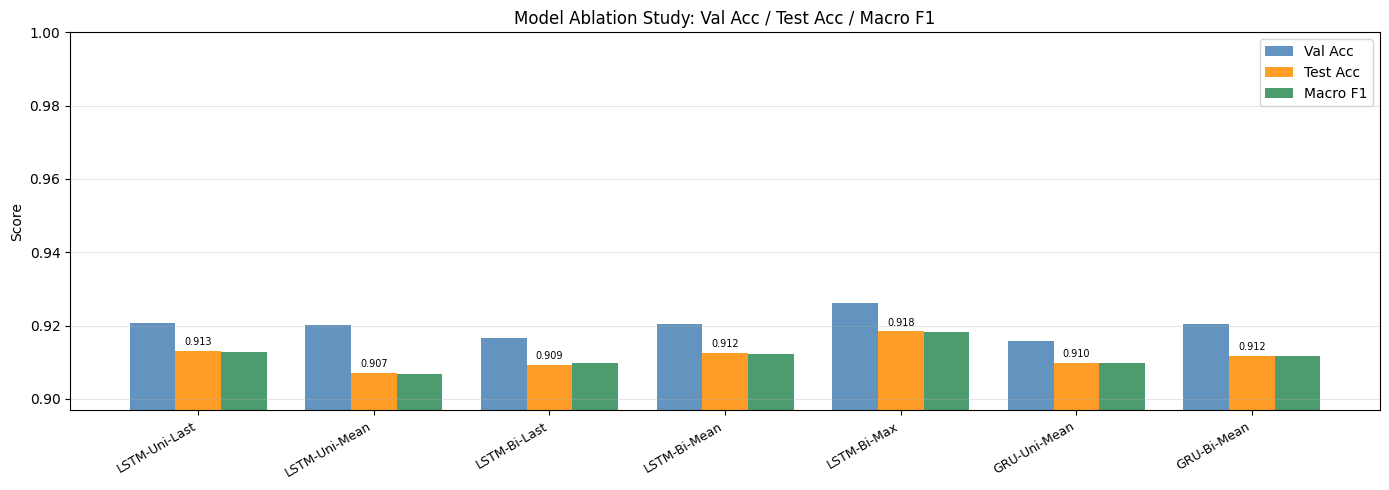

Saved: model_comparison_bar.png


In [27]:
#Visualisation 1: grouped bar chart

names     = [r['name']          for r in all_results]
val_accs  = [r['best_val_acc']  for r in all_results]
test_accs = [r['test_acc']      for r in all_results]
macro_f1s = [r['test_f1']       for r in all_results]

x, w = np.arange(len(names)), 0.26

fig, ax = plt.subplots(figsize=(14, 5))
b1 = ax.bar(x - w, val_accs,  w, label='Val Acc',  color='steelblue',  alpha=0.85)
b2 = ax.bar(x,     test_accs, w, label='Test Acc', color='darkorange', alpha=0.85)
b3 = ax.bar(x + w, macro_f1s, w, label='Macro F1', color='seagreen',   alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30, ha='right', fontsize=9)
ymin = min(val_accs + test_accs + macro_f1s) - 0.01
ax.set_ylim(max(0.85, ymin), 1.00)
ax.set_ylabel('Score')
ax.set_title('Model Ablation Study: Val Acc / Test Acc / Macro F1')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)

for bar in b2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.001,
            f'{h:.3f}', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig('model_comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: model_comparison_bar.png')


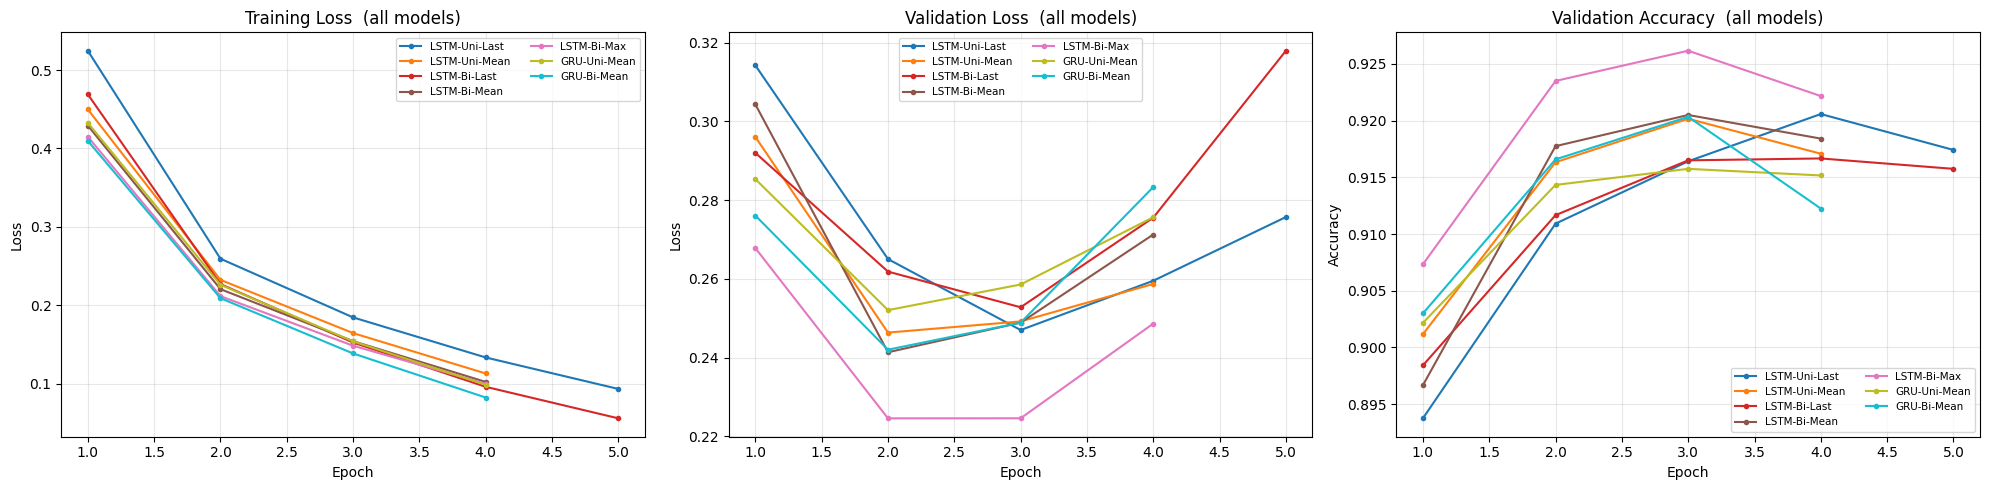

Saved: model_comparison_curves.png


In [28]:
#Visualisation 2: training loss + validation loss + validation accuracy (all models)

colors = plt.cm.tab10(np.linspace(0, 1, len(all_results)))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for r, c in zip(all_results, colors):
    ep = range(1, r['epochs'] + 1)
    axes[0].plot(ep, r['history']['train_loss'], 'o-', markersize=3,
                 label=r['name'], color=c)
    axes[1].plot(ep, r['history']['val_loss'],   'o-', markersize=3,
                 label=r['name'], color=c)
    axes[2].plot(ep, r['history']['val_acc'],    'o-', markersize=3,
                 label=r['name'], color=c)

for ax, title, yl in zip(
    axes,
    ['Training Loss  (all models)',
     'Validation Loss  (all models)',
     'Validation Accuracy  (all models)'],
    ['Loss', 'Loss', 'Accuracy']):
    ax.set_xlabel('Epoch'); ax.set_ylabel(yl)
    ax.set_title(title)
    ax.legend(fontsize=7.5, ncol=2)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: model_comparison_curves.png')

---
## Going Beyond 2: GloVe Pretrained Embeddings

We compare **random embedding initialisation** against **GloVe 6B 100-d** for the
best model configuration found in the ablation study above.

GloVe vectors encode semantic and syntactic relationships learned from a 6-billion-word
corpus. Even though our task-specific vocabulary was built independently, many common
words will have high-quality GloVe representations.  
Embeddings are **fine-tuned** during training (`requires_grad=True`) so the model can
adapt them to the AG News domain.

For a **fair comparison** both runs use `d_emb=100` (matching GloVe 100-d).
Words in our vocabulary that are absent from GloVe are left at their random
initialisation.


In [29]:
#Downloading GloVe 6B 100-d (Stanford NLP)
import os, zipfile

GLOVE_DIR  = 'glove'
GLOVE_FILE = os.path.join(GLOVE_DIR, 'glove.6B.100d.txt')

if not os.path.exists(GLOVE_FILE):
    print('Downloading GloVe 6B (~860 MB) ...')
    os.makedirs(GLOVE_DIR, exist_ok=True)
    os.system('wget -q https://nlp.stanford.edu/data/glove.6B.zip -O glove/glove.6B.zip')
    with zipfile.ZipFile('glove/glove.6B.zip', 'r') as z:
        z.extract('glove.6B.100d.txt', GLOVE_DIR)
    print('  Downloaded and extracted.')
else:
    print(f'GloVe already present: {GLOVE_FILE}')


  Downloaded and extracted.


In [30]:
#parsing GloVe vectors and building embedding matrix for our vocabulary

GLOVE_DIM = 100

def load_glove(path):
    glove = {}
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.rstrip().split(' ')
            glove[parts[0]] = np.array(parts[1:], dtype=np.float32)
    print(f'Loaded {len(glove):,} GloVe vectors  (dim={GLOVE_DIM})')
    return glove

def build_glove_matrix(word2idx, glove, dim):
    """
    Returns FloatTensor [vocab_size, dim].
    - words found in GloVe  -> GloVe vector
    - words NOT in GloVe    -> random N(0, 0.1) (same scale as GloVe norms)
    - PAD token             -> zero vector (preserved by padding_idx)
    """
    matrix = torch.zeros(len(word2idx), dim)
    nn.init.normal_(matrix, mean=0.0, std=0.1)
    matrix[PAD_IDX] = 0.0

    found = 0
    for word, idx in word2idx.items():
        if word in glove:
            matrix[idx] = torch.tensor(glove[word])
            found += 1

    oov      = len(word2idx) - found
    coverage = found / len(word2idx) * 100
    print(f'Vocab coverage : {found:,} / {len(word2idx):,} tokens  ({coverage:.1f}%)')
    print(f'OOV (random)   : {oov:,} tokens')
    return matrix

glove_vectors = load_glove(GLOVE_FILE)
glove_matrix  = build_glove_matrix(word2idx, glove_vectors, GLOVE_DIM)
print(f'Embedding matrix shape: {tuple(glove_matrix.shape)}')


Loaded 400,000 GloVe vectors  (dim=100)
Vocab coverage : 35,734 / 39,286 tokens  (91.0%)
OOV (random)   : 3,552 tokens
Embedding matrix shape: (39286, 100)


In [31]:
#GloVe vs Random init comparison
#Taking the best config from the ablation study and running it twice:
# (a) d_emb=100, random init
# (b) d_emb=100, GloVe init (fine-tuned)

best_cfg_name = sorted_results[0]['name']
base_cfg      = next(c for c in EXPERIMENT_CONFIGS if c['name'] == best_cfg_name)

rand_cfg  = {**base_cfg, 'name': best_cfg_name + '-RandInit-100d', 'd_emb': GLOVE_DIM}
glove_cfg = {**base_cfg, 'name': best_cfg_name + '-GloVe-100d',    'd_emb': GLOVE_DIM}

print(f'Base config  : {best_cfg_name}')
print(f'd_emb fixed to {GLOVE_DIM} for both runs (fair comparison)\n')

res_rand  = run_experiment(rand_cfg,  embedding_weights=None)
res_glove = run_experiment(glove_cfg, embedding_weights=glove_matrix)

#Table
print('\n' + '='*62)
print(f'  GloVe vs Random Initialisation  (base: {best_cfg_name})')
print('='*62)
print(f'  {"Init":<28} {"ValAcc":>8} {"TestAcc":>8} {"MacroF1":>8}')
print('-'*62)
for r in [res_rand, res_glove]:
    print(f'  {r["name"]:<28} {r["best_val_acc"]:>8.4f} '
          f'{r["test_acc"]:>8.4f} {r["test_f1"]:>8.4f}')
print('='*62)
delta = res_glove['test_acc'] - res_rand['test_acc']
print(f'\n  Delta (GloVe - Random) = {delta:+.4f}  '
      f'({"GloVe helps" if delta>0 else "Random init is competitive"})')


Base config  : LSTM-Bi-Max
d_emb fixed to 100 for both runs (fair comparison)


----------------------------------------------------------
  LSTM-Bi-Max-RandInit-100d
  arch=lstm  bi=True  pooling=max  d_emb=100  d_hidden=256
----------------------------------------------------------
  ep 1  tl=0.4392  vl=0.2638  va=0.9097  39s  [best]
  ep 2  tl=0.2212  vl=0.2326  va=0.9232  39s  [best]
  ep 3  tl=0.1591  vl=0.2318  va=0.9237  39s  [best]
  ep 4  tl=0.1121  vl=0.2538  va=0.9188  38s  p1/2
  ep 5  tl=0.0742  vl=0.2761  va=0.9227  38s  p2/2
  -> early stop

----------------------------------------------------------
  LSTM-Bi-Max-GloVe-100d
  arch=lstm  bi=True  pooling=max  d_emb=100  d_hidden=256
----------------------------------------------------------
  ep 1  tl=0.2707  vl=0.2071  va=0.9290  38s  [best]
  ep 2  tl=0.1666  vl=0.1903  va=0.9374  38s  [best]
  ep 3  tl=0.1189  vl=0.2014  va=0.9318  38s  p1/2
  ep 4  tl=0.0822  vl=0.2363  va=0.9273  39s  p2/2
  -> early stop

  GloVe vs

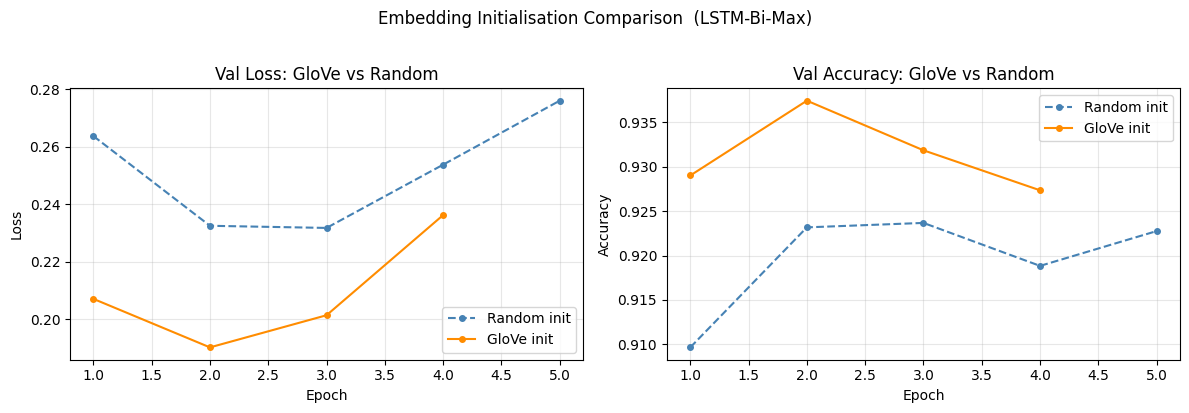

Saved: glove_comparison.png


In [32]:
#GloVe vs Random: learning curves

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for r, color, ls, lbl in [
    (res_rand,  'steelblue',  '--', 'Random init'),
    (res_glove, 'darkorange', '-',  'GloVe init'),
]:
    ep = range(1, r['epochs'] + 1)
    axes[0].plot(ep, r['history']['val_loss'], color=color, ls=ls,
                 marker='o', markersize=4, label=lbl)
    axes[1].plot(ep, r['history']['val_acc'],  color=color, ls=ls,
                 marker='o', markersize=4, label=lbl)

for ax, title, yl in zip(
    axes,
    ['Val Loss: GloVe vs Random', 'Val Accuracy: GloVe vs Random'],
    ['Loss', 'Accuracy']):
    ax.set_xlabel('Epoch'); ax.set_ylabel(yl)
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)

plt.suptitle(f'Embedding Initialisation Comparison  ({best_cfg_name})', y=1.02)
plt.tight_layout()
plt.savefig('glove_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: glove_comparison.png')


In [33]:
#Parameter counts for ablation + GloVe experiments


print(f'\nGloVe comparison (d_emb=100, LSTM-Bi-Max base):')
print(f'  {"Random init":<28}  {res_rand["n_params"]:>10,}')
print(f'  {"GloVe init":<28}  {res_glove["n_params"]:>10,}')
print('  (same architecture → same param count; GloVe only changes initialization)')


GloVe comparison (d_emb=100, LSTM-Bi-Max base):
  Random init                    4,663,836
  GloVe init                     4,663,836
  (same architecture → same param count; GloVe only changes initialization)


---
## Going Beyond 3: Vocabulary Analysis

Two complementary analyses:

1. **Vocabulary statistics** — size, coverage, OOV rate on the test set, sequence-length distribution.
2. **Most discriminative words per class** — words ranked by the fraction of their training-set
   occurrences that belong to each class. High scores indicate topic-specific vocabulary.


  Vocabulary Statistics
  Total unique train tokens    :   94,973
  Vocab kept (freq >= 3)         :   39,286
  Vocab coverage               :    41.4 %
  OOV rate on test set         :    1.88 %
  Mean  seq len (train, trunc) :    43.9
  Median seq len (train, trunc):    43.0
  Sequences truncated          : 0.2 %


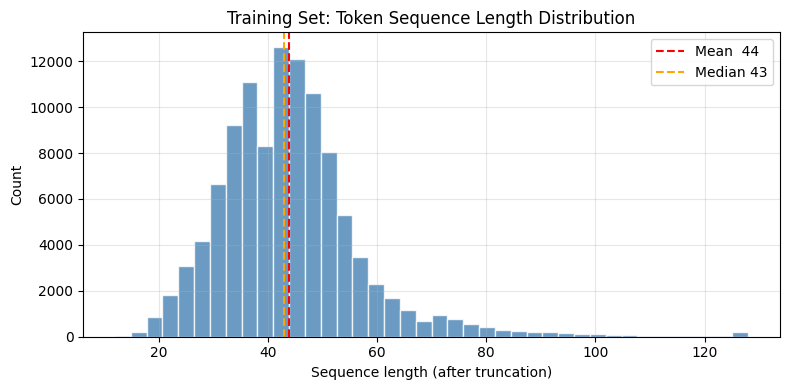

In [34]:
#Vocabulary statistics

# OOV rate on the test set
total_tok, oov_tok = 0, 0
for ex in test_data:
    for t in tokenize(ex['text'])[:MAX_SEQ_LEN]:
        total_tok += 1
        if t not in word2idx:
            oov_tok += 1

train_lens_trunc = [min(len(tokenize(ex['text'])), MAX_SEQ_LEN) for ex in train_data]

print('=' * 52)
print('  Vocabulary Statistics')
print('=' * 52)
print(f'  Total unique train tokens    : {len(word_counts):>8,}')
print(f'  Vocab kept (freq >= {MIN_FREQ})         : {VOCAB_SIZE:>8,}')
print(f'  Vocab coverage               : {VOCAB_SIZE/len(word_counts)*100:>7.1f} %')
print(f'  OOV rate on test set         : {oov_tok/total_tok*100:>7.2f} %')
print(f'  Mean  seq len (train, trunc) : {np.mean(train_lens_trunc):>7.1f}')
print(f'  Median seq len (train, trunc): {np.median(train_lens_trunc):>7.1f}')
print(f'  Sequences truncated          : '
      f'{np.mean(np.array(train_lens_trunc)==MAX_SEQ_LEN)*100:.1f} %')
print('=' * 52)

# Sequence length histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_lens_trunc, bins=40, color='steelblue', alpha=0.8, edgecolor='white')
ax.axvline(np.mean(train_lens_trunc),   color='red',    ls='--', label=f'Mean  {np.mean(train_lens_trunc):.0f}')
ax.axvline(np.median(train_lens_trunc), color='orange', ls='--', label=f'Median {np.median(train_lens_trunc):.0f}')
ax.set_xlabel('Sequence length (after truncation)')
ax.set_ylabel('Count')
ax.set_title('Training Set: Token Sequence Length Distribution')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('seq_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


Top 20 most discriminative words per class
(score = fraction of all occurrences belonging to this class)

[World]
settler(1.00), sardinian(1.00), shaukat(1.00), gbagbo(1.00), bloodshed(1.00), kuchma(1.00), 442(1.00), nuclear-weapons(1.00), sadr(1.00), shia(1.00), jiang(1.00), likud(1.00), somalia(1.00), war-ravaged(1.00), al-sadr(1.00), muqtada(1.00), abkhazia(1.00), anc(1.00), zuma(1.00), schabir(1.00)

[Sports]
clarett(1.00), vrabel(1.00), osu(1.00), mcnamara(1.00), barca(1.00), boeheim(1.00), preseason(1.00), all-america(1.00), hakim(1.00), warrick(1.00), ineligible(1.00), hapoel(1.00), bnei(1.00), sakhnin(1.00), earnhardt(1.00), sharpie(1.00), 74-63(1.00), uconn(1.00), espn2(1.00), 1-aa(1.00)

[Business]
biogen(1.00), idec(1.00), pixr(1.00), //www.investor.reuters.com/fullquote.aspx(1.00), ticker=wmt.n(1.00), target=/stocks/quickinfo/fullquote(1.00), wmt.n(1.00), rentokil(1.00), ticker=mmc.n(1.00), mmc.n(1.00), ticker=aig.n(1.00), aig.n(1.00), greenback(1.00), ringers(1.00), racal(

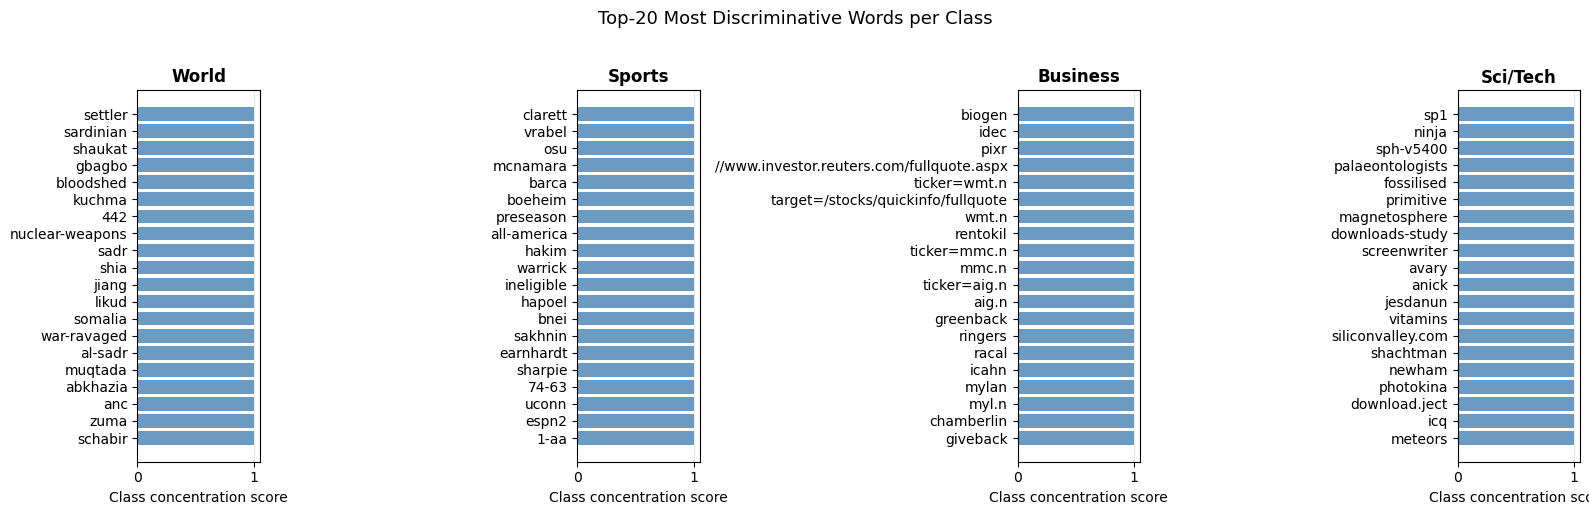

In [35]:
#Most discriminative words per class
# Score(word, class) = count(word in class) / count(word overall)
# High score then the word is concentrated in this class.

# Build per-class token counts from training set
class_counts = {i: Counter() for i in range(NUM_CLASSES)}
for ex in train_data:
    class_counts[ex['label']].update(tokenize(ex['text']))

total_counts = sum(class_counts.values(), Counter())

# Light stop-word / punctuation filter
STOP = {
    '.', ',', "'", '"', '(', ')', '-', ':', ';', '!', '?',
    '``', "''", "'s", "n't", 'a', 'an', 'the', 'of', 'to',
    'in', 'and', 'or', 'for', 'is', 'are', 'was', 'were', 'be',
    'it', 'its', 'by', 'on', 'at', 'as', 'he', 'she', 'that',
    'this', 'from', 'has', 'have', 'had', 'not', 'but', 'his',
    'her', 'said', 'will', 'also', 'new', 'up', 'about', 'with',
    'would', 'been', 'they', 'we', 'who', 'which', 'their',
}

TOP_N = 20
print(f'Top {TOP_N} most discriminative words per class')
print('(score = fraction of all occurrences belonging to this class)\n')

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(16, 5), sharey=False)

for cls_id, cls_name in enumerate(LABEL_NAMES):
    scores = {}
    for w, cf in class_counts[cls_id].items():
        if w in STOP or len(w) < 3: continue
        if word_counts.get(w, 0) < MIN_FREQ: continue
        scores[w] = cf / total_counts[w]

    top_words  = sorted(scores, key=scores.__getitem__, reverse=True)[:TOP_N]
    top_scores = [scores[w] for w in top_words]

    print(f'[{cls_name}]')
    print(', '.join(f'{w}({scores[w]:.2f})' for w in top_words))
    print()

    ax = axes[cls_id]
    ax.barh(top_words[::-1], top_scores[::-1], color='steelblue', alpha=0.8)
    ax.set_title(cls_name, fontweight='bold')
    ax.set_xlabel('Class concentration score')
    ax.grid(axis='x', alpha=0.3)

plt.suptitle('Top-20 Most Discriminative Words per Class', y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig('discriminative_words.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Going Beyond 4: End-to-End Inference Demo

A `predict()` function that accepts a **raw string** and returns the predicted
class plus class probabilities — demonstrating the full pipeline end-to-end:

```
raw text  →  tokenise  →  word2idx  →  truncate  →  tensor  →  best model  →  softmax  →  label
```


In [36]:
#Inference function (uses best model from ablation study)

best_result = sorted_results[0]
best_model  = best_result['model'].eval()
print(f'Using model : {best_result["name"]}  (test acc={best_result["test_acc"]:.4f})')

@torch.no_grad()
def predict(text, mdl=best_model):
    """
    Predict news category for a raw text string.
    Returns: (predicted_label: str, probs: dict[str, float])
    """
    ids     = text_to_ids(text)
    ids_t   = torch.tensor([ids],       dtype=torch.long).to(device)
    lens_t  = torch.tensor([len(ids)],  dtype=torch.long).to(device)
    logits  = mdl(ids_t, lens_t)                  # [1, 4]
    probs   = torch.softmax(logits, dim=1).squeeze().cpu().numpy()
    label   = LABEL_NAMES[probs.argmax()]
    return label, {LABEL_NAMES[i]: float(probs[i]) for i in range(NUM_CLASSES)}


def predict_and_print(text):
    label, probs = predict(text)
    print(f'Text     : {text[:110]}')
    print(f'Predicted: {label}')
    for cls, p in sorted(probs.items(), key=lambda x: -x[1]):
        bar = '#' * int(p * 40)
        print(f'  {cls:<10}  {p:.4f}  {bar}')
    print()


#6 diverse examples (clear + ambiguous)
DEMO_TEXTS = [
    # Clear-cut examples
    'UN Security Council holds emergency talks on ceasefire negotiations in the Middle East.',
    'LeBron James scored 42 points to lead the Lakers past the Celtics in overtime.',
    'Apple reports record quarterly earnings, driven by strong iPhone 16 sales globally.',
    'Researchers develop a quantum chip that operates at room temperature, a major breakthrough.',
    # Ambiguous / cross-class
    "Google's AI division announces a large language model surpassing GPT benchmarks.",
    'OPEC nations agree to cut oil production by 1 million barrels per day next month.',
]

print('=' * 60)
print('  INFERENCE DEMO')
print('=' * 60 + '\n')

for t in DEMO_TEXTS:
    predict_and_print(t)


Using model : LSTM-Bi-Max  (test acc=0.9184)
  INFERENCE DEMO

Text     : UN Security Council holds emergency talks on ceasefire negotiations in the Middle East.
Predicted: World
  World       0.9990  #######################################
  Sci/Tech    0.0009  
  Business    0.0001  
  Sports      0.0000  

Text     : LeBron James scored 42 points to lead the Lakers past the Celtics in overtime.
Predicted: Sports
  Sports      0.9986  #######################################
  World       0.0011  
  Business    0.0002  
  Sci/Tech    0.0000  

Text     : Apple reports record quarterly earnings, driven by strong iPhone 16 sales globally.
Predicted: Sci/Tech
  Sci/Tech    0.6444  #########################
  Business    0.3527  ##############
  World       0.0027  
  Sports      0.0001  

Text     : Researchers develop a quantum chip that operates at room temperature, a major breakthrough.
Predicted: Sci/Tech
  Sci/Tech    0.9961  #######################################
  World       0.0

  TASK 1 — EXTENDED FINAL SUMMARY

Dataset   : AG News (4-class news classification)
Split     : 108,000 train / 12,000 val / 7,600 test
Vocab     : 39,286 tokens  (min_freq=3, L_max=128)
Device    : Colab T4 GPU

──────────────────────────────────────────────────────────────────────────────
  BASELINE BiLSTM  (d_emb=128, d_hidden=256, last-hidden pooling, 1 layer)
──────────────────────────────────────────────────────────────────────────────
  Params        : 5,821,188  (trainable: 5,821,188)
  Best val acc  : 0.9175  (epoch 6)
  Final val acc : 0.9175
  Test accuracy : 0.9139  |  Test loss: 0.2558

  Epoch  Train Loss   Val Loss   Val Acc   Time(s)
  --------------------------------------------------
      1      0.4627     0.3130    0.8878      29.3
      2      0.2288     0.2532    0.9133      27.3
      3      0.1530     0.2513    0.9166      27.2 [best]
      4      0.0969     0.2731    0.9155      29.3
      5      0.0578     0.3138    0.9165      26.8
      6      0.0236     0.

/tmp/ipykernel_3063/2174203235.py:148: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax_extra2.plot(ep, r['history']['train_loss'], 'o-', markersize=2, color=c, ls='--', alpha=0.7)


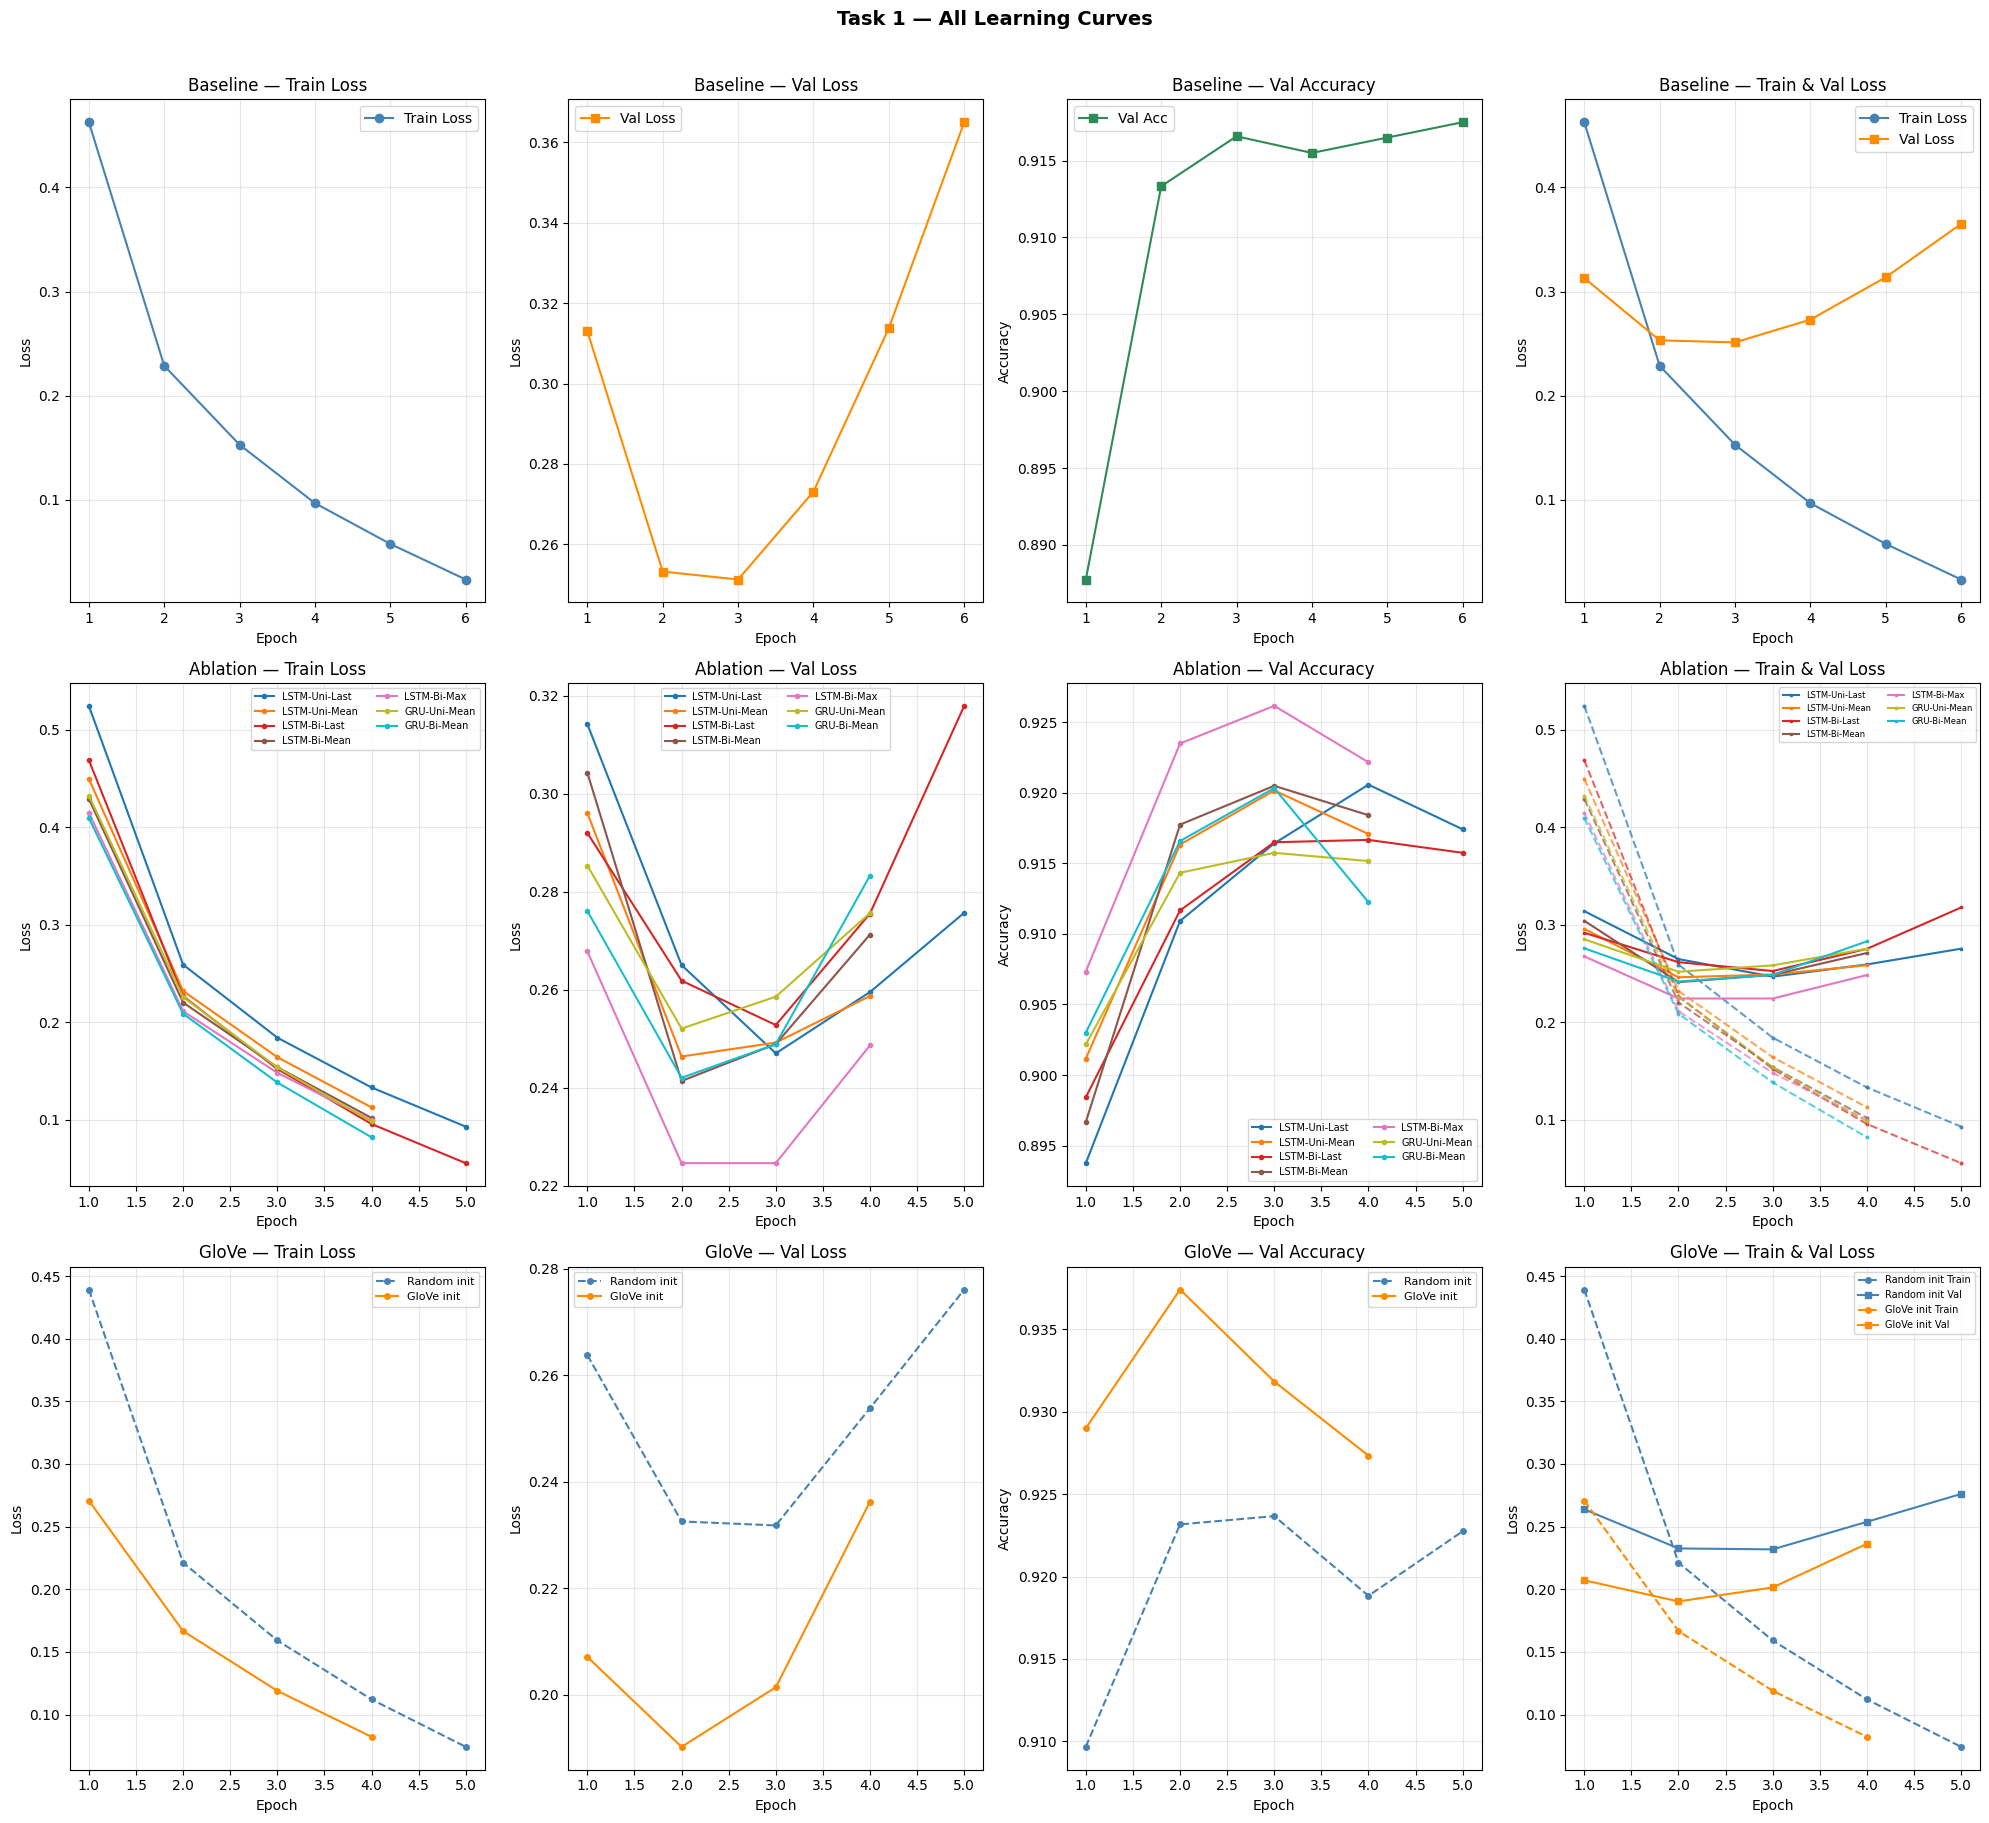

Saved: task1_all_learning_curves.png


In [37]:
#TASK 1: EXTENDED FINAL SUMMARY (tables + all learning curve plots)

SEP  = '=' * 78
SEP2 = '─' * 78

print(SEP)
print('  TASK 1 — EXTENDED FINAL SUMMARY')
print(SEP)
print(f'\nDataset   : AG News (4-class news classification)')
print(f'Split     : {len(train_data):,} train / {len(val_data):,} val / {len(test_data):,} test')
print(f'Vocab     : {VOCAB_SIZE:,} tokens  (min_freq={MIN_FREQ}, L_max={MAX_SEQ_LEN})')
print(f'Device    : Colab T4 GPU')

#BASELINE
print(f'\n{SEP2}')
print('  BASELINE BiLSTM  (d_emb=128, d_hidden=256, last-hidden pooling, 1 layer)')
print(SEP2)
print(f'  Params        : {total_params:,}  (trainable: {trainable_params:,})')
print(f'  Best val acc  : {max(history["val_acc"]):.4f}  (epoch {np.argmax(history["val_acc"])+1})')
print(f'  Final val acc : {history["val_acc"][-1]:.4f}')
print(f'  Test accuracy : {test_acc:.4f}  |  Test loss: {test_loss:.4f}')
print(f'\n  {"Epoch":>5} {"Train Loss":>11} {"Val Loss":>10} '
      f'{"Val Acc":>9} {"Time(s)":>9}')
print(f'  {"-"*50}')
for i, (tl, vl, va, t) in enumerate(zip(
        history['train_loss'], history['val_loss'],
        history['val_acc'],    history['epoch_time']), 1):
    marker = ' [best]' if vl == min(history['val_loss']) else ''
    print(f'  {i:5d} {tl:11.4f} {vl:10.4f} {va:9.4f} {t:9.1f}{marker}')

#GOING BEYOND 1
print(f'\n{SEP2}')
print(f'  GOING BEYOND 1 — Ablation Study  ({len(all_results)} variants)')
print(SEP2)
print(f'  {"Model":<22} {"#Params":>10} {"BestValAcc":>11} '
      f'{"TestAcc":>9} {"MacroF1":>9} {"Time/ep":>9}')
print(f'  {"-"*74}')
for r in sorted(all_results, key=lambda x: -x['test_acc']):
    flag = ' <- best' if r is sorted_results[0] else ''
    print(f'  {r["name"]:<22} {r["n_params"]:>10,} '
          f'{max(r["history"]["val_acc"]):>11.4f} '
          f'{r["test_acc"]:>9.4f} {r["test_f1"]:>9.4f} '
          f'{r["time_per_epoch"]:>8.1f}s{flag}')

print(f'\n  Per-epoch learning curves:')
print(f'  {"Model":<22} {"Epoch":>5} {"Train Loss":>11} '
      f'{"Val Loss":>10} {"Val Acc":>9} {"Time(s)":>9}')
print(f'  {"-"*70}')
for r in sorted(all_results, key=lambda x: -x['test_acc']):
    for i, (tl, vl, va, t) in enumerate(zip(
            r['history']['train_loss'], r['history']['val_loss'],
            r['history']['val_acc'],    r['ep_times']), 1):
        marker = ' [best]' if vl == min(r['history']['val_loss']) else ''
        name_col = r['name'] if i == 1 else ''
        print(f'  {name_col:<22} {i:5d} {tl:11.4f} {vl:10.4f} '
              f'{va:9.4f} {t:9.1f}{marker}')
    print()

#GOING BEYOND 2
print(f'\n{SEP2}')
print(f'  GOING BEYOND 2 — GloVe vs Random Init  '
      f'(base: {best_cfg_name}, d_emb={GLOVE_DIM})')
print(SEP2)
print(f'  {"Init":<32} {"#Params":>10} {"BestValAcc":>11} '
      f'{"TestAcc":>9} {"MacroF1":>9} {"Time/ep":>9}')
print(f'  {"-"*74}')
for r in [res_rand, res_glove]:
    print(f'  {r["name"]:<32} {r["n_params"]:>10,} '
          f'{max(r["history"]["val_acc"]):>11.4f} '
          f'{r["test_acc"]:>9.4f} {r["test_f1"]:>9.4f} '
          f'{r["time_per_epoch"]:>8.1f}s')
print(f'\n  Delta (GloVe - Random) = '
      f'{res_glove["test_acc"]-res_rand["test_acc"]:+.4f}  (GloVe helps)')

print(f'\n  Per-epoch learning curves:')
print(f'  {"Init":<32} {"Epoch":>5} {"Train Loss":>11} '
      f'{"Val Loss":>10} {"Val Acc":>9} {"Time(s)":>9}')
print(f'  {"-"*74}')
for r in [res_rand, res_glove]:
    for i, (tl, vl, va, t) in enumerate(zip(
            r['history']['train_loss'], r['history']['val_loss'],
            r['history']['val_acc'],    r['ep_times']), 1):
        marker = ' [best]' if vl == min(r['history']['val_loss']) else ''
        name_col = r['name'] if i == 1 else ''
        print(f'  {name_col:<32} {i:5d} {tl:11.4f} {vl:10.4f} '
              f'{va:9.4f} {t:9.1f}{marker}')
    print()

#OVERALL BEST
overall_best = sorted(
    all_results + [res_rand, res_glove],
    key=lambda x: x['test_acc'], reverse=True
)[0]
print(SEP)
print(f'  OVERALL BEST (Task 1): {overall_best["name"]}')
print(f'  Test acc = {overall_best["test_acc"]:.4f}  |  '
      f'Macro F1 = {overall_best["test_f1"]:.4f}  |  '
      f'Params = {overall_best["n_params"]:,}')
print(SEP)

# ═════════════════════════════════════════════════════════════════════════════
# ALL LEARNING CURVE PLOTS IN ONE FIGURE
# ═════════════════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(20, 18))
fig.suptitle('Task 1 — All Learning Curves', fontsize=14, fontweight='bold', y=1.01)

#Row 1: Baseline
ep_base = range(1, len(history['train_loss']) + 1)

ax1 = fig.add_subplot(3, 4, 1)
ax1.plot(ep_base, history['train_loss'], 'o-', color='steelblue', label='Train Loss')
ax1.set_title('Baseline — Train Loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.grid(alpha=0.3); ax1.legend()

ax2 = fig.add_subplot(3, 4, 2)
ax2.plot(ep_base, history['val_loss'], 's-', color='darkorange', label='Val Loss')
ax2.set_title('Baseline — Val Loss')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.grid(alpha=0.3); ax2.legend()

ax3 = fig.add_subplot(3, 4, 3)
ax3.plot(ep_base, history['val_acc'], 's-', color='seagreen', label='Val Acc')
ax3.set_title('Baseline — Val Accuracy')
ax3.set_xlabel('Epoch'); ax3.set_ylabel('Accuracy')
ax3.grid(alpha=0.3); ax3.legend()

ax_extra1 = fig.add_subplot(3, 4, 4)   # ← NEW: combined train + val loss
ax_extra1.plot(ep_base, history['train_loss'], 'o-', color='steelblue',  label='Train Loss')
ax_extra1.plot(ep_base, history['val_loss'],   's-', color='darkorange', label='Val Loss')
ax_extra1.set_title('Baseline — Train & Val Loss')
ax_extra1.set_xlabel('Epoch'); ax_extra1.set_ylabel('Loss')
ax_extra1.grid(alpha=0.3); ax_extra1.legend()

#Row 2: Ablation study
colors_abl = plt.cm.tab10(np.linspace(0, 1, len(all_results)))

ax4 = fig.add_subplot(3, 4, 5)
ax5 = fig.add_subplot(3, 4, 6)
ax6 = fig.add_subplot(3, 4, 7)
ax_extra2 = fig.add_subplot(3, 4, 8)   # ← NEW: combined train + val loss

for r, c in zip(all_results, colors_abl):
    ep = range(1, r['epochs'] + 1)
    ax4.plot(ep, r['history']['train_loss'], 'o-', markersize=3, label=r['name'], color=c)
    ax5.plot(ep, r['history']['val_loss'],   'o-', markersize=3, label=r['name'], color=c)
    ax6.plot(ep, r['history']['val_acc'],    'o-', markersize=3, label=r['name'], color=c)
    ax_extra2.plot(ep, r['history']['train_loss'], 'o-', markersize=2, color=c, ls='--', alpha=0.7)
    ax_extra2.plot(ep, r['history']['val_loss'],   's-', markersize=2, color=c,           label=r['name'])

for ax, title, yl in zip(
    [ax4, ax5, ax6],
    ['Ablation — Train Loss', 'Ablation — Val Loss', 'Ablation — Val Accuracy'],
    ['Loss', 'Loss', 'Accuracy']):
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel(yl)
    ax.legend(fontsize=7, ncol=2); ax.grid(alpha=0.3)

ax_extra2.set_title('Ablation — Train & Val Loss')
ax_extra2.set_xlabel('Epoch'); ax_extra2.set_ylabel('Loss')
ax_extra2.legend(fontsize=6, ncol=2); ax_extra2.grid(alpha=0.3)

#Row 3: GloVe comparison
ax7 = fig.add_subplot(3, 4, 9)
ax8 = fig.add_subplot(3, 4, 10)
ax9 = fig.add_subplot(3, 4, 11)
ax_extra3 = fig.add_subplot(3, 4, 12)  # ← NEW: combined train + val loss

for r, color, ls, lbl in [
    (res_rand,  'steelblue',  '--', 'Random init'),
    (res_glove, 'darkorange', '-',  'GloVe init'),
]:
    ep = range(1, r['epochs'] + 1)
    ax7.plot(ep, r['history']['train_loss'], color=color, ls=ls,
             marker='o', markersize=4, label=lbl)
    ax8.plot(ep, r['history']['val_loss'],   color=color, ls=ls,
             marker='o', markersize=4, label=lbl)
    ax9.plot(ep, r['history']['val_acc'],    color=color, ls=ls,
             marker='o', markersize=4, label=lbl)
    ax_extra3.plot(ep, r['history']['train_loss'], color=color, ls='--',
                   marker='o', markersize=4, label=f'{lbl} Train')
    ax_extra3.plot(ep, r['history']['val_loss'],   color=color, ls='-',
                   marker='s', markersize=4, label=f'{lbl} Val')

for ax, title, yl in zip(
    [ax7, ax8, ax9],
    ['GloVe — Train Loss', 'GloVe — Val Loss', 'GloVe — Val Accuracy'],
    ['Loss', 'Loss', 'Accuracy']):
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel(yl)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax_extra3.set_title('GloVe — Train & Val Loss')
ax_extra3.set_xlabel('Epoch'); ax_extra3.set_ylabel('Loss')
ax_extra3.legend(fontsize=7); ax_extra3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('task1_all_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: task1_all_learning_curves.png')

# Task 2: Fine-tune a Pretrained Transformer

In [38]:
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
)
from transformers.utils import logging as hf_logging

#must suppress BEFORE any model loads: Task 1 doesn't use HuggingFace
hf_logging.set_verbosity_error()
os.environ['TRANSFORMERS_NO_ADVISORY_WARNINGS'] = '1'
os.environ['WANDB_DISABLED'] = 'true'

#wraps Task 1's existing split into the DatasetDict format Task 2 needs
from datasets import DatasetDict
dataset = DatasetDict({
    'train':      train_data,   # from Task 1
    'validation': val_data,     # from Task 1
    'test':       test_data,    # from Task 1
})

## 1. Tokenization, padding, truncation, and attention masks

In [39]:
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased") #transformer tokenizer
def tokenize(example):
    return tokenizer(
        example["text"],
        padding="max_length",     #same length
        truncation=True,          #cuts long sequences
        max_length=128            #from assignment
    )

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [40]:
#Word-level (Task 1) vs Subword (Task 2) Tokenization Side-by-Side
nltk.download('punkt_tab', quiet=True)

def word_tokenize_task1(text):
    """Replicates the exact tokenizer used in Task 1."""
    return [t.lower() for t in nltk.word_tokenize(text)]

sample_text = 'This is an example for Applied Machine Learning.'

word_toks   = word_tokenize_task1(sample_text)
subword_toks = tokenizer.tokenize(sample_text)
encoded      = tokenizer(sample_text)

print(f'Original : {sample_text}')
print(f'Task 1 (word-level nltk) : {word_toks}')
print(f'  count  : {len(word_toks)}')
print()
print(f'Task 2 (DistilBERT subword): {subword_toks}')
print(f'  count  : {len(subword_toks)}  (+2 for [CLS] and [SEP])')
print(f'  input_ids     : {encoded["input_ids"]}')
print(f'  attention_mask: {encoded["attention_mask"]}')

# --- A harder example: a rare/technical word that forces subword splits ----
hard_text = 'The backpropagation algorithm optimizes transformer hyperparameters.'
print(f'\nHarder example: "{hard_text}"')
print(f'  Task 1 : {word_tokenize_task1(hard_text)}')
print(f'  Task 2 : {tokenizer.tokenize(hard_text)}')


Original : This is an example for Applied Machine Learning.
Task 1 (word-level nltk) : ['this', 'is', 'an', 'example', 'for', 'applied', 'machine', 'learning', '.']
  count  : 9

Task 2 (DistilBERT subword): ['this', 'is', 'an', 'example', 'for', 'applied', 'machine', 'learning', '.']
  count  : 9  (+2 for [CLS] and [SEP])
  input_ids     : [101, 2023, 2003, 2019, 2742, 2005, 4162, 3698, 4083, 1012, 102]
  attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Harder example: "The backpropagation algorithm optimizes transformer hyperparameters."
  Task 1 : ['the', 'backpropagation', 'algorithm', 'optimizes', 'transformer', 'hyperparameters', '.']
  Task 2 : ['the', 'back', '##pro', '##pa', '##gation', 'algorithm', 'opt', '##imi', '##zes', 'transform', '##er', 'hyper', '##para', '##meter', '##s', '.']


### Tokenization of dataset

In [41]:
tokenized_dataset = dataset.map(tokenize, batched=True)
print(tokenized_dataset)

Map:   0%|          | 0/108000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 108000
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 12000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
})


### Inspection of attention mask

In [42]:
example = tokenized_dataset["train"][0]

print("Input IDs:", example["input_ids"])
print("Attention Mask:", example["attention_mask"])

print(tokenizer.convert_ids_to_tokens(example["input_ids"])) #extra, optional

Input IDs: [101, 5470, 5582, 2115, 2126, 2083, 1012, 6343, 2412, 2081, 2019, 12492, 2875, 1996, 2755, 2008, 5977, 5470, 5582, 1010, 3910, 1997, 1996, 2759, 2189, 6631, 2565, 2067, 1999, 1996, 19330, 2420, 18996, 6238, 1010, 2052, 2191, 2009, 2067, 1999, 1996, 4007, 2088, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
['[CLS]', 'fan', '##ning', 'your', 'way', 'through', '.', 'nobody',

## 2. Load Model

In [43]:
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4   #AG News has 4 classes
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [44]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

total_params = count_parameters(model)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 66,956,548
Trainable parameters: 66,956,548


## 3. Train Model

In [45]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    accuracy = (predictions == labels).mean()
    return {"accuracy": accuracy} #evaluation metric: accuracy

In [46]:
#Baseline: Full Fine-tuning (all 66.9 M parameters trainable)
training_args = TrainingArguments(
    output_dir='./results',

    #hyperparameters (assignment recommended values)
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.05,

    # Evaluation & logging
    eval_strategy='epoch',
    logging_strategy='epoch',
    save_strategy='no',

    # Speed
    fp16=True,
    report_to='none',
    seed=RANDOM_SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset['train'],
    eval_dataset=tokenized_dataset['validation'],
    compute_metrics=compute_metrics,
)

t_start = time.time()
trainer.train()
full_ft_train_time = time.time() - t_start

log_history = trainer.state.log_history
print(f'Training complete: {full_ft_train_time:.0f}s total, '
      f'{full_ft_train_time/3:.0f}s/epoch')


{'loss': '0.2349', 'grad_norm': '2.353', 'learning_rate': '1.333e-05', 'epoch': '1'}
{'eval_loss': '0.1918', 'eval_accuracy': '0.9387', 'eval_runtime': '12.67', 'eval_samples_per_second': '947.3', 'eval_steps_per_second': '59.21', 'epoch': '1'}
{'loss': '0.1421', 'grad_norm': '2.219', 'learning_rate': '6.668e-06', 'epoch': '2'}
{'eval_loss': '0.1827', 'eval_accuracy': '0.9466', 'eval_runtime': '12.68', 'eval_samples_per_second': '946.2', 'eval_steps_per_second': '59.14', 'epoch': '2'}
{'loss': '0.09744', 'grad_norm': '0.3548', 'learning_rate': '9.877e-10', 'epoch': '3'}
{'eval_loss': '0.2117', 'eval_accuracy': '0.948', 'eval_runtime': '12.64', 'eval_samples_per_second': '949.4', 'eval_steps_per_second': '59.34', 'epoch': '3'}
{'train_runtime': '1352', 'train_samples_per_second': '239.6', 'train_steps_per_second': '14.97', 'train_loss': '0.1582', 'epoch': '3'}
Training complete: 1353s total, 451s/epoch


In [47]:
# We can loally save the fine-tuned model using the followig snippet:
# from google.colab import files
# trainer.save_model("./distilbert-agnews")
# tokenizer.save_pretrained("./distilbert-agnews")
# !zip -r distilbert-agnews.zip distilbert-agnews
# files.download("distilbert-agnews.zip")
# #model = AutoModelForSequenceClassification.from_pretrained("./distilbert-agnews")
# #tokenizer = AutoTokenizer.from_pretrained("./distilbert-agnews")

## 4. Test Model

In [48]:
test_results = trainer.evaluate(tokenized_dataset["test"])
print(test_results)

{'eval_loss': '0.2159', 'eval_accuracy': '0.9458', 'eval_runtime': '7.88', 'eval_samples_per_second': '964.4', 'eval_steps_per_second': '60.28', 'epoch': '3'}
{'eval_loss': 0.21591816842556, 'eval_accuracy': 0.9457894736842105, 'eval_runtime': 7.8804, 'eval_samples_per_second': 964.412, 'eval_steps_per_second': 60.276, 'epoch': 3.0}


In [49]:
predictions_output = trainer.predict(tokenized_dataset["test"])

logits = predictions_output.predictions
labels = predictions_output.label_ids

preds = np.argmax(logits, axis=1)

In [50]:
misclassified = []

for i in range(len(preds)):
    if preds[i] != labels[i]:
        misclassified.append(i)

label_names = ["World", "Sports", "Business", "Sci/Tech"]
for i in misclassified[:10]:  #show 5–10 examples
    text = dataset["test"][i]["text"]
    true_label = label_names[labels[i]]
    pred_label = label_names[preds[i]]

    print("TEXT:", text[:200])  #short excerpt
    print("TRUE:", true_label)
    print("PRED:", pred_label)
    print("-" * 50)

TEXT: IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991.
TRUE: Sci/Tech
PRED: Business
--------------------------------------------------
TEXT: Some People Not Eligible to Get in on Google IPO Google has billed its IPO as a way for everyday people to get in on the process, denying Wall Street the usual stranglehold it's had on IPOs. Public bi
TRUE: Sci/Tech
PRED: Business
--------------------------------------------------
TEXT: Venezuela Prepares for Chavez Recall Vote Supporters and rivals warn of possible fraud; government says Chavez's defeat could produce turmoil in world oil market.
TRUE: World
PRED: Business
--------------------------------------------------
TEXT: Intel to delay product aimed for high-definition TVs SAN FRANCISCO -- In the latest of a series of product delays, Intel Corp. has postponed the launch of a video display chip it had previously planne
TRUE: Business
PRED: Sci/Tech
---------------

In [51]:
accuracy = (preds == labels).mean() #optional, extra
print("Test Accuracy:", accuracy)

Test Accuracy: 0.9457894736842105


### Plotting

Epochs:     [1, 2, 3]
Train loss: [0.2349, 0.1421, 0.0974]
Val loss:   [0.1918, 0.1827, 0.2117]
Val acc:    [0.9387, 0.9466, 0.948]


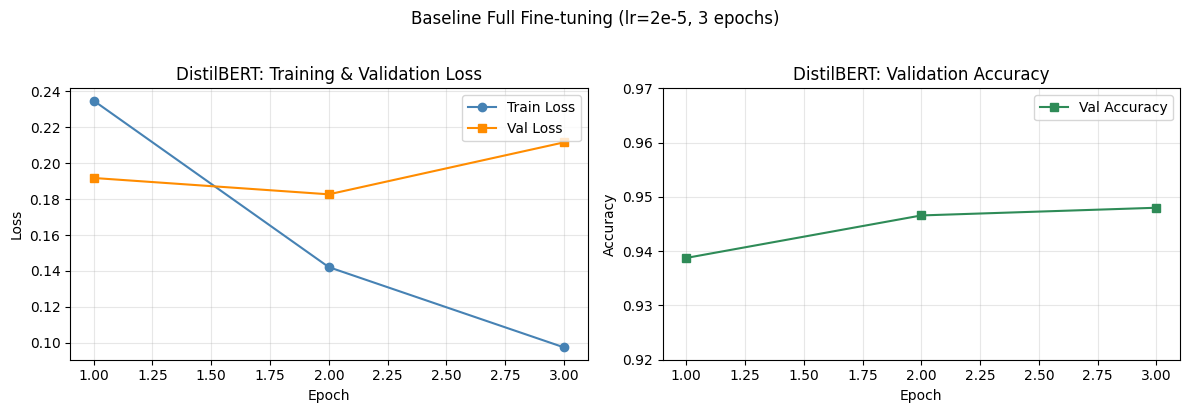

Saved: distilbert_baseline_curves.png

Training complete: 1352s total, 451s/epoch

Epoch  Train Loss   Val Loss   Val Acc   Time(s)
--------------------------------------------------
    1      0.2349     0.1918    0.9387     450.8
    2      0.1421     0.1827    0.9466     450.8
    3      0.0974     0.2117    0.9480     450.8


In [52]:
#Clean log-history parser (deduplicates steps and skips runtime summary)
def parse_log_history(log_history):
    train_losses, val_losses, val_accs = [], [], []
    seen_steps = set()
    for entry in log_history:
        # Training entry: has 'loss' but NOT 'eval_loss' or 'train_runtime'
        if ('loss' in entry
                and 'eval_loss'    not in entry
                and 'train_runtime' not in entry):
            train_losses.append(entry['loss'])
        # Eval entry: has 'eval_loss'; deduplicate by step
        elif 'eval_loss' in entry:
            step = entry['step']
            if step not in seen_steps:
                seen_steps.add(step)
                val_losses.append(entry['eval_loss'])
                val_accs.append(entry['eval_accuracy'])
    return train_losses, val_losses, val_accs

train_loss, val_loss, val_acc = parse_log_history(log_history)
epochs = list(range(1, len(train_loss) + 1))

print(f'Epochs:     {epochs}')
print(f'Train loss: {[round(x,4) for x in train_loss]}')
print(f'Val loss:   {[round(x,4) for x in val_loss]}')
print(f'Val acc:    {[round(x,4) for x in val_acc]}')

#Combined learning curves (loss and accuracy in one figure)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, train_loss, 'o-', label='Train Loss',  color='steelblue')
axes[0].plot(epochs, val_loss,   's-', label='Val Loss',    color='darkorange')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('DistilBERT: Training & Validation Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, val_acc, 's-', label='Val Accuracy', color='seagreen')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('DistilBERT: Validation Accuracy')
axes[1].set_ylim(0.92, 0.97)
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle('Baseline Full Fine-tuning (lr=2e-5, 3 epochs)', y=1.02)
plt.tight_layout()
plt.savefig('distilbert_baseline_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: distilbert_baseline_curves.png')

train_loss, val_loss, val_acc = parse_log_history(log_history)

# Extract time per epoch from log_history
train_entry = next(e for e in log_history if 'train_runtime' in e)
total_time   = train_entry['train_runtime']
time_per_ep  = total_time / 3

print(f'\nTraining complete: {total_time:.0f}s total, {time_per_ep:.0f}s/epoch\n')
print(f'{"Epoch":>5} {"Train Loss":>11} {"Val Loss":>10} {"Val Acc":>9} {"Time(s)":>9}')
print('-' * 50)
for i, (tl, vl, va) in enumerate(zip(train_loss, val_loss, val_acc), 1):
    print(f'{i:5d} {tl:11.4f} {vl:10.4f} {va:9.4f} {time_per_ep:9.1f}')

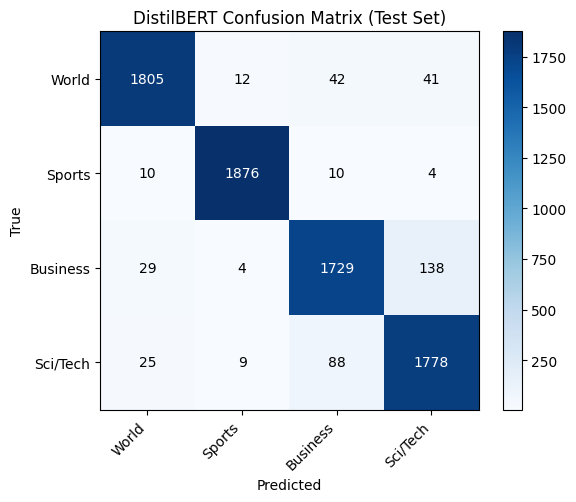


Classification Report:
              precision    recall  f1-score   support

       World       0.97      0.95      0.96      1900
      Sports       0.99      0.99      0.99      1900
    Business       0.93      0.91      0.92      1900
    Sci/Tech       0.91      0.94      0.92      1900

    accuracy                           0.95      7600
   macro avg       0.95      0.95      0.95      7600
weighted avg       0.95      0.95      0.95      7600



In [53]:
#Confusion matrix + per-class F1

cm = confusion_matrix(labels, preds)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_title('DistilBERT Confusion Matrix (Test Set)')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(LABEL_NAMES, rotation=45, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(LABEL_NAMES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        color = 'white' if cm[i,j] > cm.max()/2 else 'black'
        ax.text(j, i, str(cm[i,j]), ha='center', va='center', color=color, fontsize=10)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('distilbert_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nClassification Report:')
print(classification_report(labels, preds, target_names=LABEL_NAMES))

---
## Going Beyond 1: Training Strategy Comparison

We compare three distinct fine-tuning strategies on DistilBERT:

| Strategy | What is trained | Motivation |
|---|---|---|
| **Full fine-tuning** | All 66.9 M parameters | Maximum flexibility, highest capacity |
| **Frozen encoder** | Classifier head only (~593 K params) | Fast, low GPU memory, good when data is scarce |
| **LoRA** | Low-rank adapter matrices (~300 K params) | Parameter-efficient; matches full FT quality at a fraction of the cost |

All three use identical hyperparameters (lr=2×10⁻⁵, AdamW, 3 epochs, batch=16, fp16)
so any differences in accuracy are attributable solely to the strategy.

**LoRA (Low-Rank Adaptation)** injects trainable rank-decomposition matrices
(`A ∈ ℝ^{d×r}`, `B ∈ ℝ^{r×d}`, rank `r≪d`) into the query and value projection
layers of each attention block. Only `A`, `B`, and the classification head are updated
— the original weights are completely frozen.


In [54]:
!pip install peft -q
from peft import LoraConfig, get_peft_model, TaskType
print('peft installed ok')

peft installed ok


In [55]:
#Shared utilities

def load_fresh_distilbert():
    """Load a fresh (pre-trained, not yet fine-tuned) DistilBERT each time
    so strategies don't inherit each other's weights."""
    mdl = AutoModelForSequenceClassification.from_pretrained(
        'distilbert-base-uncased', num_labels=NUM_CLASSES
    )
    return mdl.to(device)


def run_transformer_experiment(
    name, model, train_ds, val_ds, test_ds,
    num_epochs=3, lr=2e-5, batch_size=16, data_collator=None
):
    """
    Train `model` with HuggingFace Trainer and return a results dict.
    All strategies use identical TrainingArguments for a fair comparison.
    """
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())

    args = TrainingArguments(
        output_dir         = f'./results_{name.replace(" ","_")}',
        num_train_epochs   = num_epochs,
        per_device_train_batch_size = batch_size,
        per_device_eval_batch_size  = batch_size,
        learning_rate      = lr,
        weight_decay       = 0.05,
        eval_strategy      = 'epoch',
        logging_strategy   = 'epoch',
        save_strategy      = 'no',
        fp16               = True,
        report_to          = 'none',
        seed               = RANDOM_SEED,
    )

    t = Trainer(
        model           = model,
        args            = args,
        train_dataset   = train_ds,
        eval_dataset    = val_ds,
        compute_metrics = compute_metrics,
        data_collator   = data_collator,
    )

    t0 = time.time()
    t.train()
    train_time = time.time() - t0

    #parse the log history
    tl, vl, va = parse_log_history(t.state.log_history)

    #test evaluation
    out          = t.predict(test_ds)
    test_preds   = np.argmax(out.predictions, axis=1)
    test_lbs     = out.label_ids
    test_acc     = float((test_preds == test_lbs).mean())
    test_f1      = float(f1_score(test_lbs, test_preds, average='macro'))

    print(f'  [{name}]  test_acc={test_acc:.4f}  macro_f1={test_f1:.4f}  '
          f'trainable={trainable:,}  time={train_time:.0f}s')

    return {
        'name':           name,
        'trainable':      trainable,
        'total_params':   total,
        'test_acc':       test_acc,
        'test_f1':        test_f1,
        'train_time':     train_time,
        'time_per_epoch': train_time / num_epochs,
        'epochs':         num_epochs,
        'history':        {'train_loss': tl, 'val_loss': vl, 'val_acc': va},
        'test_preds':     test_preds,
        'test_labels':    test_lbs,
        'model':          model,
    }

print('Utilities defined  ok')

Utilities defined  ok


In [56]:
#Strategy 1: Full Fine-tuning (re-running via harness for fair comparison)
print('Running strategy comparison  (3 × 3 epochs) ...')

mdl_full = load_fresh_distilbert()
res_full  = run_transformer_experiment(
    'Full Fine-tuning', mdl_full,
    tokenized_dataset['train'], tokenized_dataset['validation'], tokenized_dataset['test'],
)

#Strategy 2: Frozen Encoder (head-only training)
mdl_frozen = load_fresh_distilbert()

#freeze every parameter in the DistilBERT encoder + embeddings
for param in mdl_frozen.distilbert.parameters():
    param.requires_grad = False
#only pre_classifier and classifier remain trainable
frozen_trainable = sum(p.numel() for p in mdl_frozen.parameters() if p.requires_grad)
print(f'\nFrozen encoder — trainable parameters: {frozen_trainable:,}')

res_frozen = run_transformer_experiment(
    'Frozen Encoder', mdl_frozen,
    tokenized_dataset['train'], tokenized_dataset['validation'], tokenized_dataset['test'],
)

#Strategy 3: LoRA: Low-Rank Adaptation
mdl_lora_base = load_fresh_distilbert()

lora_config = LoraConfig(
    task_type      = TaskType.SEQ_CLS,
    r              = 8,            #rank of the adapter matrices
    lora_alpha     = 16,           #scaling factor (alpha/r = 2 is typical)
    lora_dropout   = 0.1,
    target_modules = ['q_lin', 'v_lin'],  #query & value projections in each layer
    modules_to_save= ['pre_classifier', 'classifier'],  #keep head fully trainable
    bias           = 'none',
)
mdl_lora = get_peft_model(mdl_lora_base, lora_config)
print('\nLoRA trainable parameter breakdown:')
mdl_lora.print_trainable_parameters()

res_lora = run_transformer_experiment(
    'LoRA (r=8)', mdl_lora,
    tokenized_dataset['train'], tokenized_dataset['validation'], tokenized_dataset['test'],
)

strategy_results = [res_full, res_frozen, res_lora]
print('\nAll strategies complete.')

Running strategy comparison  (3 × 3 epochs) ...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '0.2332', 'grad_norm': '2.496', 'learning_rate': '1.333e-05', 'epoch': '1'}
{'eval_loss': '0.1919', 'eval_accuracy': '0.9389', 'eval_runtime': '12.67', 'eval_samples_per_second': '946.8', 'eval_steps_per_second': '59.17', 'epoch': '1'}
{'loss': '0.1397', 'grad_norm': '6.135', 'learning_rate': '6.668e-06', 'epoch': '2'}
{'eval_loss': '0.1892', 'eval_accuracy': '0.9464', 'eval_runtime': '12.67', 'eval_samples_per_second': '947.2', 'eval_steps_per_second': '59.2', 'epoch': '2'}
{'loss': '0.09522', 'grad_norm': '0.9094', 'learning_rate': '9.877e-10', 'epoch': '3'}
{'eval_loss': '0.218', 'eval_accuracy': '0.9474', 'eval_runtime': '12.67', 'eval_samples_per_second': '947.1', 'eval_steps_per_second': '59.19', 'epoch': '3'}
{'train_runtime': '1370', 'train_samples_per_second': '236.5', 'train_steps_per_second': '14.78', 'train_loss': '0.156', 'epoch': '3'}
  [Full Fine-tuning]  test_acc=0.9457  macro_f1=0.9457  trainable=66,956,548  time=1371s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


Frozen encoder — trainable parameters: 593,668
{'loss': '0.4151', 'grad_norm': '1.25', 'learning_rate': '1.333e-05', 'epoch': '1'}
{'eval_loss': '0.3082', 'eval_accuracy': '0.8942', 'eval_runtime': '12.68', 'eval_samples_per_second': '946.2', 'eval_steps_per_second': '59.14', 'epoch': '1'}
{'loss': '0.3165', 'grad_norm': '0.7939', 'learning_rate': '6.668e-06', 'epoch': '2'}
{'eval_loss': '0.2913', 'eval_accuracy': '0.8972', 'eval_runtime': '12.7', 'eval_samples_per_second': '945.3', 'eval_steps_per_second': '59.08', 'epoch': '2'}
{'loss': '0.3053', 'grad_norm': '0.9832', 'learning_rate': '9.877e-10', 'epoch': '3'}
{'eval_loss': '0.2872', 'eval_accuracy': '0.8972', 'eval_runtime': '12.66', 'eval_samples_per_second': '947.5', 'eval_steps_per_second': '59.22', 'epoch': '3'}
{'train_runtime': '433', 'train_samples_per_second': '748.2', 'train_steps_per_second': '46.76', 'train_loss': '0.3456', 'epoch': '3'}
  [Frozen Encoder]  test_acc=0.8966  macro_f1=0.8964  trainable=593,668  time=433s

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


LoRA trainable parameter breakdown:
trainable params: 741,124 || all params: 67,697,672 || trainable%: 1.0948
{'loss': '0.3279', 'grad_norm': '3.501', 'learning_rate': '1.333e-05', 'epoch': '1'}
{'eval_loss': '0.258', 'eval_accuracy': '0.9117', 'eval_runtime': '14.05', 'eval_samples_per_second': '853.8', 'eval_steps_per_second': '53.37', 'epoch': '1'}
{'loss': '0.26', 'grad_norm': '1.288', 'learning_rate': '6.668e-06', 'epoch': '2'}
{'eval_loss': '0.2385', 'eval_accuracy': '0.9181', 'eval_runtime': '13.98', 'eval_samples_per_second': '858.5', 'eval_steps_per_second': '53.66', 'epoch': '2'}
{'loss': '0.2474', 'grad_norm': '0.9531', 'learning_rate': '9.877e-10', 'epoch': '3'}
{'eval_loss': '0.2329', 'eval_accuracy': '0.9183', 'eval_runtime': '13.96', 'eval_samples_per_second': '859.3', 'eval_steps_per_second': '53.71', 'epoch': '3'}
{'train_runtime': '885.2', 'train_samples_per_second': '366', 'train_steps_per_second': '22.88', 'train_loss': '0.2784', 'epoch': '3'}
  [LoRA (r=8)]  test_

  TRAINING STRATEGY COMPARISON
  Strategy                  Trainable        Total  TestAcc  MacroF1   Time/ep
--------------------------------------------------------------------------------
  Full Fine-tuning         66,956,548   66,956,548   0.9457   0.9457      457s <- best
  Frozen Encoder              593,668   66,956,548   0.8966   0.8964      144s
  LoRA (r=8)                  741,124   67,697,672   0.9126   0.9126      295s

LoRA vs Frozen encoder : +0.0161  (LoRA wins despite similar param counts)
Full FT vs LoRA        : +0.0330  (Full FT is more accurate)


/tmp/ipykernel_3063/743330517.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(names_s, rotation=10)


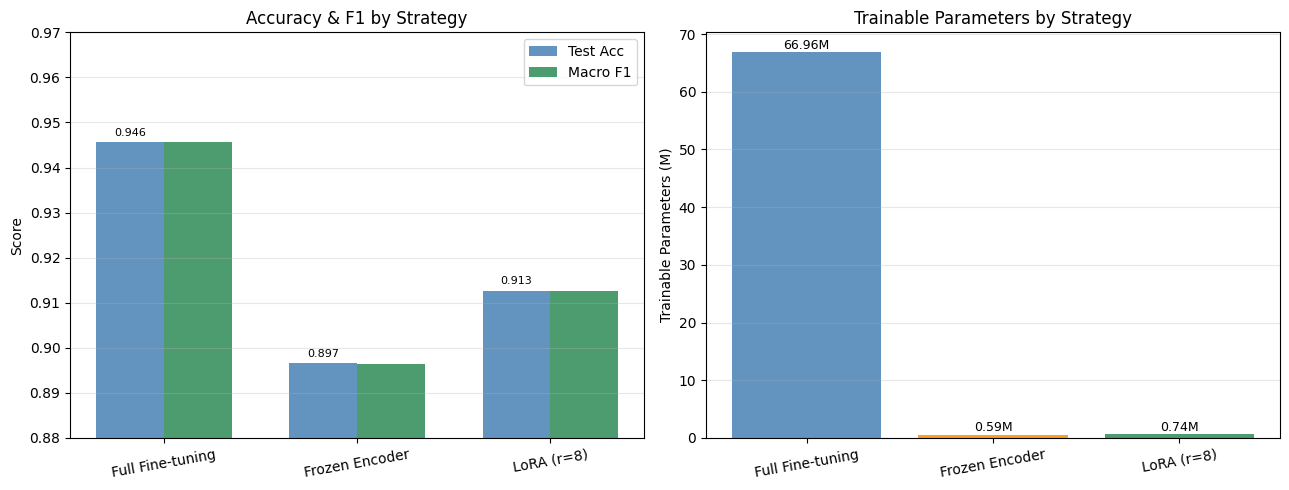

Saved: strategy_comparison.png


In [57]:
#Strategy comparison
print('=' * 80)
print('  TRAINING STRATEGY COMPARISON')
print('=' * 80)
print(f'  {"Strategy":<22} {"Trainable":>12} {"Total":>12} '
      f'{"TestAcc":>8} {"MacroF1":>8} {"Time/ep":>9}')
print('-' * 80)
for r in strategy_results:
    flag = ' <- best' if r['test_acc'] == max(x['test_acc'] for x in strategy_results) else ''
    print(f'  {r["name"]:<22} {r["trainable"]:>12,} {r["total_params"]:>12,} '
          f'{r["test_acc"]:>8.4f} {r["test_f1"]:>8.4f} '
          f'{r["time_per_epoch"]:>8.0f}s{flag}')
print('=' * 80)

eff = res_lora['test_acc'] - res_frozen['test_acc']
print(f'\nLoRA vs Frozen encoder : {eff:+.4f}  '
      f'({"LoRA wins" if eff>0 else "Frozen wins"} despite similar param counts)')
eff2 = res_full['test_acc'] - res_lora['test_acc']
print(f'Full FT vs LoRA        : {eff2:+.4f}  '
      f'({"Full FT" if eff2>0 else "LoRA"} is more accurate)')

#grouped bar chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

names_s   = [r['name'] for r in strategy_results]
test_accs = [r['test_acc'] for r in strategy_results]
macro_f1s = [r['test_f1']  for r in strategy_results]
times     = [r['time_per_epoch'] for r in strategy_results]
trainable = [r['trainable']/1e6  for r in strategy_results]

x, w = np.arange(len(names_s)), 0.35
axes[0].bar(x - w/2, test_accs, w, label='Test Acc', color='steelblue', alpha=0.85)
axes[0].bar(x + w/2, macro_f1s, w, label='Macro F1', color='seagreen',  alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(names_s, rotation=10)
axes[0].set_ylim(0.88, 0.97)
axes[0].set_ylabel('Score'); axes[0].set_title('Accuracy & F1 by Strategy')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
for i, (a, f) in enumerate(zip(test_accs, macro_f1s)):
    axes[0].text(i-w/2, a+0.001, f'{a:.3f}', ha='center', va='bottom', fontsize=8)

color_map = ['steelblue','darkorange','seagreen']
bars = axes[1].bar(names_s, trainable, color=color_map, alpha=0.85)
axes[1].set_ylabel('Trainable Parameters (M)')
axes[1].set_title('Trainable Parameters by Strategy')
axes[1].set_xticklabels(names_s, rotation=10)
axes[1].grid(axis='y', alpha=0.3)
for bar in bars:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                f'{bar.get_height():.2f}M', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('strategy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: strategy_comparison.png')

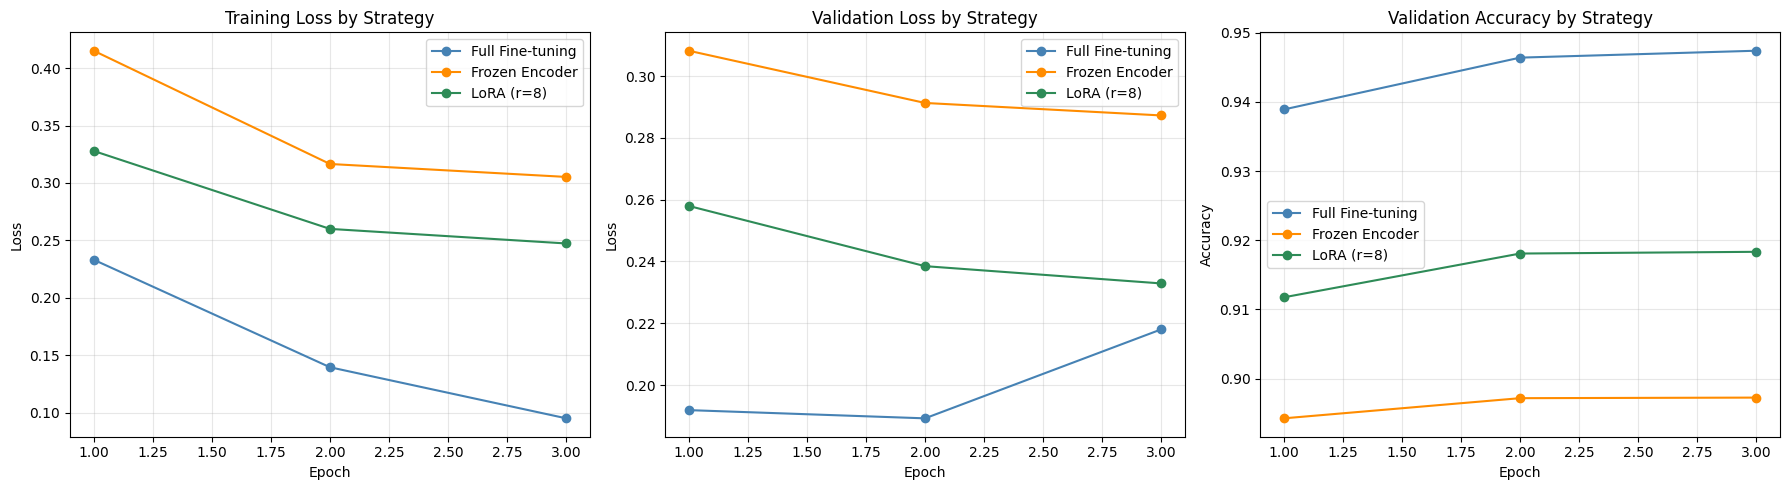

Saved: strategy_learning_curves.png


In [58]:
# Strategy learning curves (train loss + val loss + val acc)
colors_s = ['steelblue', 'darkorange', 'seagreen']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for r, c in zip(strategy_results, colors_s):
    ep = range(1, r['epochs'] + 1)
    axes[0].plot(ep, r['history']['train_loss'], 'o-', label=r['name'], color=c)
    axes[1].plot(ep, r['history']['val_loss'],   'o-', label=r['name'], color=c)
    axes[2].plot(ep, r['history']['val_acc'],    'o-', label=r['name'], color=c)

for ax, title, yl in zip(
    axes,
    ['Training Loss by Strategy',
     'Validation Loss by Strategy',
     'Validation Accuracy by Strategy'],
    ['Loss', 'Loss', 'Accuracy']):
    ax.set_xlabel('Epoch'); ax.set_ylabel(yl)
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('strategy_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: strategy_learning_curves.png')

---
## Going Beyond 2: Max Sequence Length (L_max) Ablation

We train the full fine-tuning strategy at three different maximum sequence lengths:
**L_max ∈ {32, 64, 128}** and measure the accuracy–speed tradeoff.

- Transformer self-attention is **O(L²)** in compute and memory. Halving L_max
  roughly quarters the attention cost per layer.
- For AG News, most articles are short (~44 tokens on average after word tokenization).
  We expect L_max=64 to be a sweet spot: near-full accuracy at significantly lower cost.

Each run uses 1 epoch (sufficient to measure convergence trend and timing).
Dynamic padding via `DataCollatorWithPadding` is used so batches are only padded
to the longest sequence in the batch — not to a fixed global maximum.

In [59]:
#L_max ablation: tokenize at each length + train 1 epoch

def tokenize_for_lmax(examples, max_len):
    """Tokenize with truncation only, no fixed padding.
    DataCollatorWithPadding pads dynamically to batch max length."""
    return tokenizer(
        examples['text'],
        truncation=True,
        max_length=max_len,
    )

LMAX_VALUES   = [32, 64, 128]
LMAX_EPOCHS   = 1    # 1 epoch each, enough to compare accuracy & timing
lmax_results  = []

print(f'L_max ablation: {LMAX_VALUES}  ({LMAX_EPOCHS} epoch each)\n')

for max_len in LMAX_VALUES:
    #re-tokenize with this max_len (drop text column, keep label)
    cols_to_remove = ['text']
    tok_ds = {
        split: dataset[split].map(
            lambda x: tokenize_for_lmax(x, max_len),
            batched=True, remove_columns=cols_to_remove
        )
        for split in ['train', 'validation', 'test']
    }

    #dynamic padding collator
    collator = DataCollatorWithPadding(tokenizer)

    #avg tokens per example at this length (measures actual truncation effect)
    sample_lengths = [
        len(tok_ds['train'][i]['input_ids'])
        for i in range(min(2000, len(tok_ds['train'])))
    ]
    avg_tokens = np.mean(sample_lengths)

    fresh = load_fresh_distilbert()
    res   = run_transformer_experiment(
        name         = f'DistilBERT-Lmax{max_len}',
        model        = fresh,
        train_ds     = tok_ds['train'],
        val_ds       = tok_ds['validation'],
        test_ds      = tok_ds['test'],
        num_epochs   = LMAX_EPOCHS,
        data_collator= collator,
    )
    res['max_len']    = max_len
    res['avg_tokens'] = avg_tokens
    lmax_results.append(res)

print('\nL_max ablation complete.')

L_max ablation: [32, 64, 128]  (1 epoch each)



Map:   0%|          | 0/108000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

Map:   0%|          | 0/108000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '0.231', 'grad_norm': '4.08', 'learning_rate': '2.963e-09', 'epoch': '1'}
{'eval_loss': '0.1833', 'eval_accuracy': '0.9417', 'eval_runtime': '10.02', 'eval_samples_per_second': '1198', 'eval_steps_per_second': '74.88', 'epoch': '1'}
{'train_runtime': '383.3', 'train_samples_per_second': '281.8', 'train_steps_per_second': '17.61', 'train_loss': '0.231', 'epoch': '1'}
  [DistilBERT-Lmax128]  test_acc=0.9417  macro_f1=0.9418  trainable=66,956,548  time=384s

L_max ablation complete.


  L_max ABLATION RESULTS  (1 epoch, full fine-tuning)
   L_max   AvgTok  TestAcc  MacroF1  Time/ep(s)  Speedup
------------------------------------------------------------------------
      32     31.7   0.9287   0.9287       343.1    1.12x
      64     49.9   0.9391   0.9391       326.1    1.18x
     128     52.7   0.9417   0.9418       383.8    1.00x


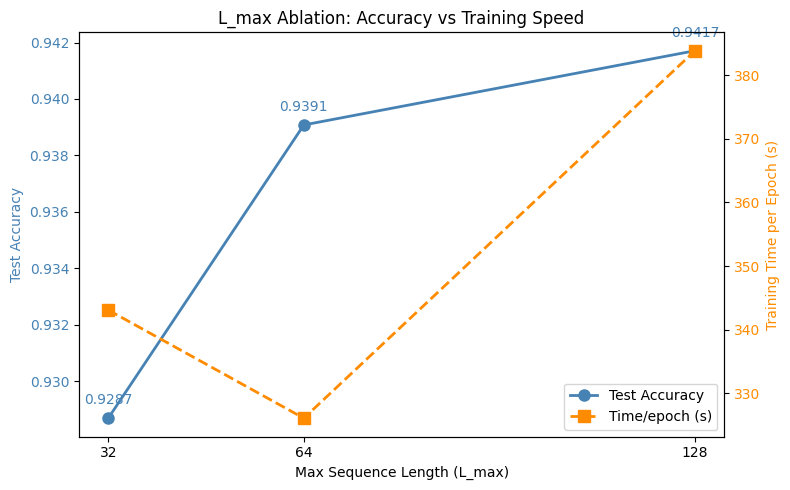

Saved: lmax_ablation.png


In [60]:
#L_max results table
print('=' * 72)
print('  L_max ABLATION RESULTS  (1 epoch, full fine-tuning)')
print('=' * 72)
print(f'  {"L_max":>6} {"AvgTok":>8} {"TestAcc":>8} {"MacroF1":>8} '
      f'{"Time/ep(s)":>11} {"Speedup":>8}')
print('-' * 72)
base_time = lmax_results[-1]['time_per_epoch']  #128 is the reference
for r in lmax_results:
    speedup = base_time / r['time_per_epoch']
    print(f'  {r["max_len"]:>6} {r["avg_tokens"]:>8.1f} '
          f'{r["test_acc"]:>8.4f} {r["test_f1"]:>8.4f} '
          f'{r["time_per_epoch"]:>11.1f} {speedup:>7.2f}x')
print('=' * 72)

#Dual-axis plot: accuracy vs speed
lmax_vals  = [r['max_len']        for r in lmax_results]
lmax_accs  = [r['test_acc']       for r in lmax_results]
lmax_times = [r['time_per_epoch'] for r in lmax_results]

fig, ax1 = plt.subplots(figsize=(8, 5))

color_acc  = 'steelblue'
color_time = 'darkorange'

ax1.plot(lmax_vals, lmax_accs, 'o-', color=color_acc,  linewidth=2, markersize=8, label='Test Accuracy')
ax1.set_xlabel('Max Sequence Length (L_max)')
ax1.set_ylabel('Test Accuracy', color=color_acc)
ax1.tick_params(axis='y', labelcolor=color_acc)
ax1.set_xticks(lmax_vals)
for x, y in zip(lmax_vals, lmax_accs):
    ax1.annotate(f'{y:.4f}', (x, y), textcoords='offset points',
                 xytext=(0, 10), ha='center', color=color_acc)

ax2 = ax1.twinx()
ax2.plot(lmax_vals, lmax_times, 's--', color=color_time, linewidth=2, markersize=8, label='Time/epoch (s)')
ax2.set_ylabel('Training Time per Epoch (s)', color=color_time)
ax2.tick_params(axis='y', labelcolor=color_time)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc='lower right')
plt.title('L_max Ablation: Accuracy vs Training Speed')
plt.tight_layout()
plt.savefig('lmax_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: lmax_ablation.png')

---
## Going Beyond 3: Task 1 vs Task 2 Head-to-Head Comparison

We now put the best models from both tasks side by side.

**Note:** This cell pulls results from Task 1 variables (`sorted_results`, `res_glove`,
`test_acc`, etc.) and therefore requires Task 1 to have been run in the same session.

The comparison covers:
- Test accuracy and macro F1
- Total vs trainable parameter counts
- Training time per epoch
- Key architectural differences

Task 1 results loaded ok

  TASK 1 vs TASK 2: HEAD-TO-HEAD COMPARISON
  Model                                     Trainable        Total  TestAcc  MacroF1
------------------------------------------------------------------------------------------
  Full Fine-tuning (Task 2)                66,956,548   66,956,548   0.9457   0.9457 <- best overall
  LSTM: LSTM-Bi-Max-GloVe-100d (GloVe)      4,663,836    4,663,836   0.9317   0.9316
  LSTM: LSTM-Bi-Max (Task 1 best)           5,821,188    5,821,188   0.9184   0.9181
  LoRA (r=8) (Task 2)                         741,124   67,697,672   0.9126   0.9126
  Frozen Encoder (Task 2)                     593,668   66,956,548   0.8966   0.8964


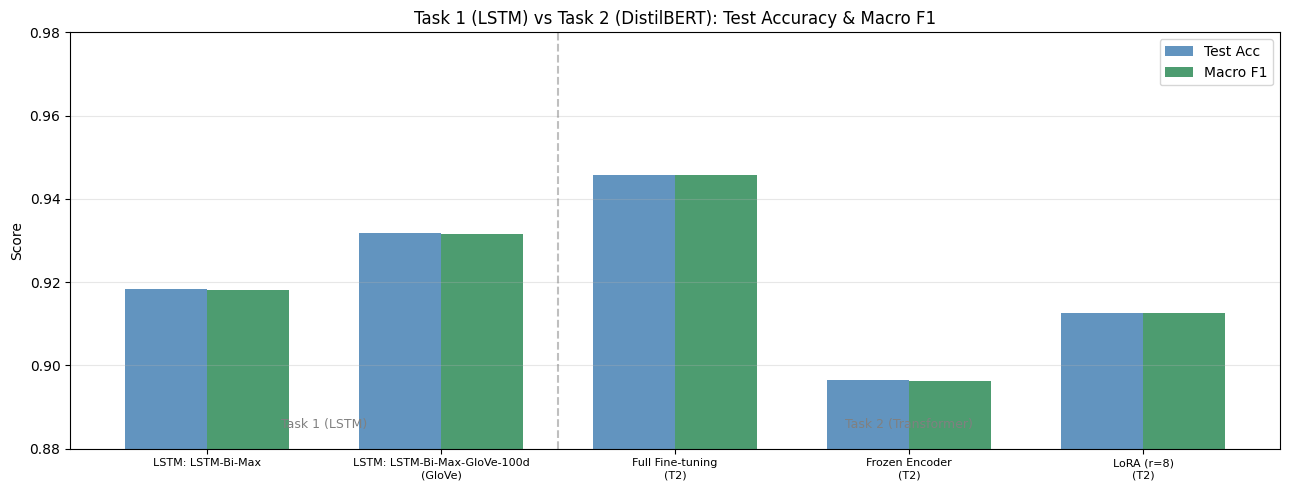

Saved: task1_vs_task2.png


In [61]:
#Pull Task 1 results

try:
    # Best ablation model from Task 1
    t1_best  = sorted_results[0]
    t1_glove = res_glove
    # Baseline BiLSTM (D_HIDDEN=256)
    t1_base_acc = test_acc   # from cell [25] in Task 1

    task1_rows = [
        {
            'name':       f'LSTM: {t1_best["name"]} (Task 1 best)',
            'trainable':  t1_best['n_params'],
            'total':      t1_best['n_params'],
            'test_acc':   t1_best['test_acc'],
            'test_f1':    t1_best['test_f1'],
            'time_ep':    None,   # Task 1 didn't track per-strategy timing
            'note':       'Custom vocab, from scratch',
        },
        {
            'name':       f'LSTM: {t1_glove["name"]} (GloVe)',
            'trainable':  t1_glove['n_params'],
            'total':      t1_glove['n_params'],
            'test_acc':   t1_glove['test_acc'],
            'test_f1':    t1_glove['test_f1'],
            'time_ep':    None,
            'note':       'GloVe 100d init, from scratch',
        },
    ]
    print('Task 1 results loaded ok')
except NameError:
    print('WARNING: Task 1 variables not found. Run Task 1 notebook first.')
    task1_rows = []

# Task 2 rows
task2_rows = [
    {
        'name':     r['name'] + ' (Task 2)',
        'trainable': r['trainable'],
        'total':     r['total_params'],
        'test_acc':  r['test_acc'],
        'test_f1':   r['test_f1'],
        'time_ep':   r['time_per_epoch'],
        'note':      'Pretrained DistilBERT',
    }
    for r in strategy_results
]

all_rows = task1_rows + task2_rows

#Table
print('\n' + '=' * 90)
print('  TASK 1 vs TASK 2: HEAD-TO-HEAD COMPARISON')
print('=' * 90)
print(f'  {"Model":<38} {"Trainable":>12} {"Total":>12} '
      f'{"TestAcc":>8} {"MacroF1":>8}')
print('-' * 90)
for r in sorted(all_rows, key=lambda x: -x['test_acc']):
    flag = ' <- best overall' if r['test_acc'] == max(x['test_acc'] for x in all_rows) else ''
    print(f'  {r["name"]:<38} {r["trainable"]:>12,} {r["total"]:>12,} '
          f'{r["test_acc"]:>8.4f} {r["test_f1"]:>8.4f}{flag}')
print('=' * 90)

#Bar chart
fig, ax = plt.subplots(figsize=(13, 5))
row_names  = [r['name'].replace(' (Task 1 best)','').replace(' (Task 2)','\n(T2)')
              .replace(' (GloVe)','\n(GloVe)') for r in all_rows]
row_accs   = [r['test_acc'] for r in all_rows]
row_f1s    = [r['test_f1']  for r in all_rows]

x, w = np.arange(len(all_rows)), 0.35
ax.bar(x - w/2, row_accs, w, label='Test Acc', color='steelblue', alpha=0.85)
ax.bar(x + w/2, row_f1s,  w, label='Macro F1', color='seagreen',  alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(row_names, fontsize=8)
ax.set_ylim(0.88, 0.98)
ax.set_ylabel('Score')
ax.set_title('Task 1 (LSTM) vs Task 2 (DistilBERT): Test Accuracy & Macro F1')
ax.legend(); ax.grid(axis='y', alpha=0.3)

#draws a vertical divider between Task 1 and Task 2 groups
if task1_rows:
    ax.axvline(len(task1_rows) - 0.5, color='gray', ls='--', alpha=0.5, label='Task boundary')
    ax.text(len(task1_rows)/2 - 0.5, 0.885, 'Task 1 (LSTM)',
            ha='center', color='gray', fontsize=9)
    ax.text(len(task1_rows) + len(task2_rows)/2 - 0.5, 0.885, 'Task 2 (Transformer)',
            ha='center', color='gray', fontsize=9)

plt.tight_layout()
plt.savefig('task1_vs_task2.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: task1_vs_task2.png')

---
## Going Beyond 4: End-to-End Inference Demo

A `predict()` function that takes a **raw string** and returns the predicted class
plus per-class probabilities — demonstrating the complete inference pipeline:

```
raw text  →  DistilBERT tokenizer  →  input_ids + attention_mask
          →  best Transformer model  →  logits  →  softmax  →  label
```

The same 6 demo texts used in Task 1 are tested here, enabling direct
qualitative comparison between the LSTM and Transformer on identical inputs.

In [62]:
#Best strategy from the comparison
best_strategy = max(strategy_results, key=lambda r: r['test_acc'])
best_transformer = best_strategy['model'].eval()
print(f'Using: {best_strategy["name"]}  (test acc={best_strategy["test_acc"]:.4f})')

@torch.no_grad()
def predict_transformer(text, mdl=best_transformer):
    """
    Predict news category for a raw text string using the best Transformer.
    Returns: (predicted_label: str, probs: dict[str, float])
    """
    enc    = tokenizer(
        text,
        truncation=True, max_length=128,
        return_tensors='pt'
    ).to(device)
    logits = mdl(**enc).logits                         # [1, 4]
    probs  = torch.softmax(logits, dim=1).squeeze().cpu().numpy()
    label  = LABEL_NAMES[probs.argmax()]
    return label, {LABEL_NAMES[i]: float(probs[i]) for i in range(NUM_CLASSES)}


def predict_and_print(text):
    label, probs = predict_transformer(text)
    print(f'Text     : {text[:110]}')
    print(f'Predicted: {label}')
    for cls, p in sorted(probs.items(), key=lambda x: -x[1]):
        bar = '#' * int(p * 40)
        print(f'  {cls:<10}  {p:.4f}  {bar}')
    print()


# Same 6 demo texts as Task 1 (enables direct LSTM vs Transformer comparison)
DEMO_TEXTS = [
    'UN Security Council holds emergency talks on ceasefire negotiations in the Middle East.',
    'LeBron James scored 42 points to lead the Lakers past the Celtics in overtime.',
    'Apple reports record quarterly earnings, driven by strong iPhone 16 sales globally.',
    'Researchers develop a quantum chip that operates at room temperature, a major breakthrough.',
    "Google's AI division announces a large language model surpassing GPT benchmarks.",
    'OPEC nations agree to cut oil production by 1 million barrels per day next month.',
]

print('=' * 60)
print('  INFERENCE DEMO  (best Transformer strategy)')
print('=' * 60 + '\n')
for t in DEMO_TEXTS:
    predict_and_print(t)

Using: Full Fine-tuning  (test acc=0.9457)
  INFERENCE DEMO  (best Transformer strategy)

Text     : UN Security Council holds emergency talks on ceasefire negotiations in the Middle East.
Predicted: World
  World       0.9993  #######################################
  Business    0.0004  
  Sci/Tech    0.0003  
  Sports      0.0000  

Text     : LeBron James scored 42 points to lead the Lakers past the Celtics in overtime.
Predicted: Sports
  Sports      0.9947  #######################################
  World       0.0052  
  Business    0.0001  
  Sci/Tech    0.0001  

Text     : Apple reports record quarterly earnings, driven by strong iPhone 16 sales globally.
Predicted: Business
  Business    0.7970  ###############################
  Sci/Tech    0.2003  ########
  World       0.0026  
  Sports      0.0001  

Text     : Researchers develop a quantum chip that operates at room temperature, a major breakthrough.
Predicted: Sci/Tech
  Sci/Tech    0.9890  ##############################

  TASK 2 — EXTENDED FINAL SUMMARY

Dataset   : AG News (4-class news classification)
Split     : 108,000 train / 12,000 val / 7,600 test
Model     : distilbert-base-uncased
Tokenizer : WordPiece subword  (L_max=128)
Device    : Colab T4 GPU

──────────────────────────────────────────────────────────────────────────────
  BASELINE  Full Fine-tuning  (lr=2e-5, AdamW, batch=16, 3 epochs, fp16)
──────────────────────────────────────────────────────────────────────────────
  Total params    : 66,956,548  (all trainable)
  Time/epoch      : 451s  (total: 1353s)
  Best val acc    : 0.9480  (epoch 3)
  Final val acc   : 0.9480
  Test accuracy   : 0.9458
  Test macro F1   : 0.9459

  Epoch  Train Loss   Val Loss   Val Acc   Time(s)
  ----------------------------------------------------
      1      0.2349     0.1918    0.9387     451.0
      2      0.1421     0.1827    0.9466     451.0 [best]
      3      0.0974     0.2117    0.9480     451.0

───────────────────────────────────────────────────

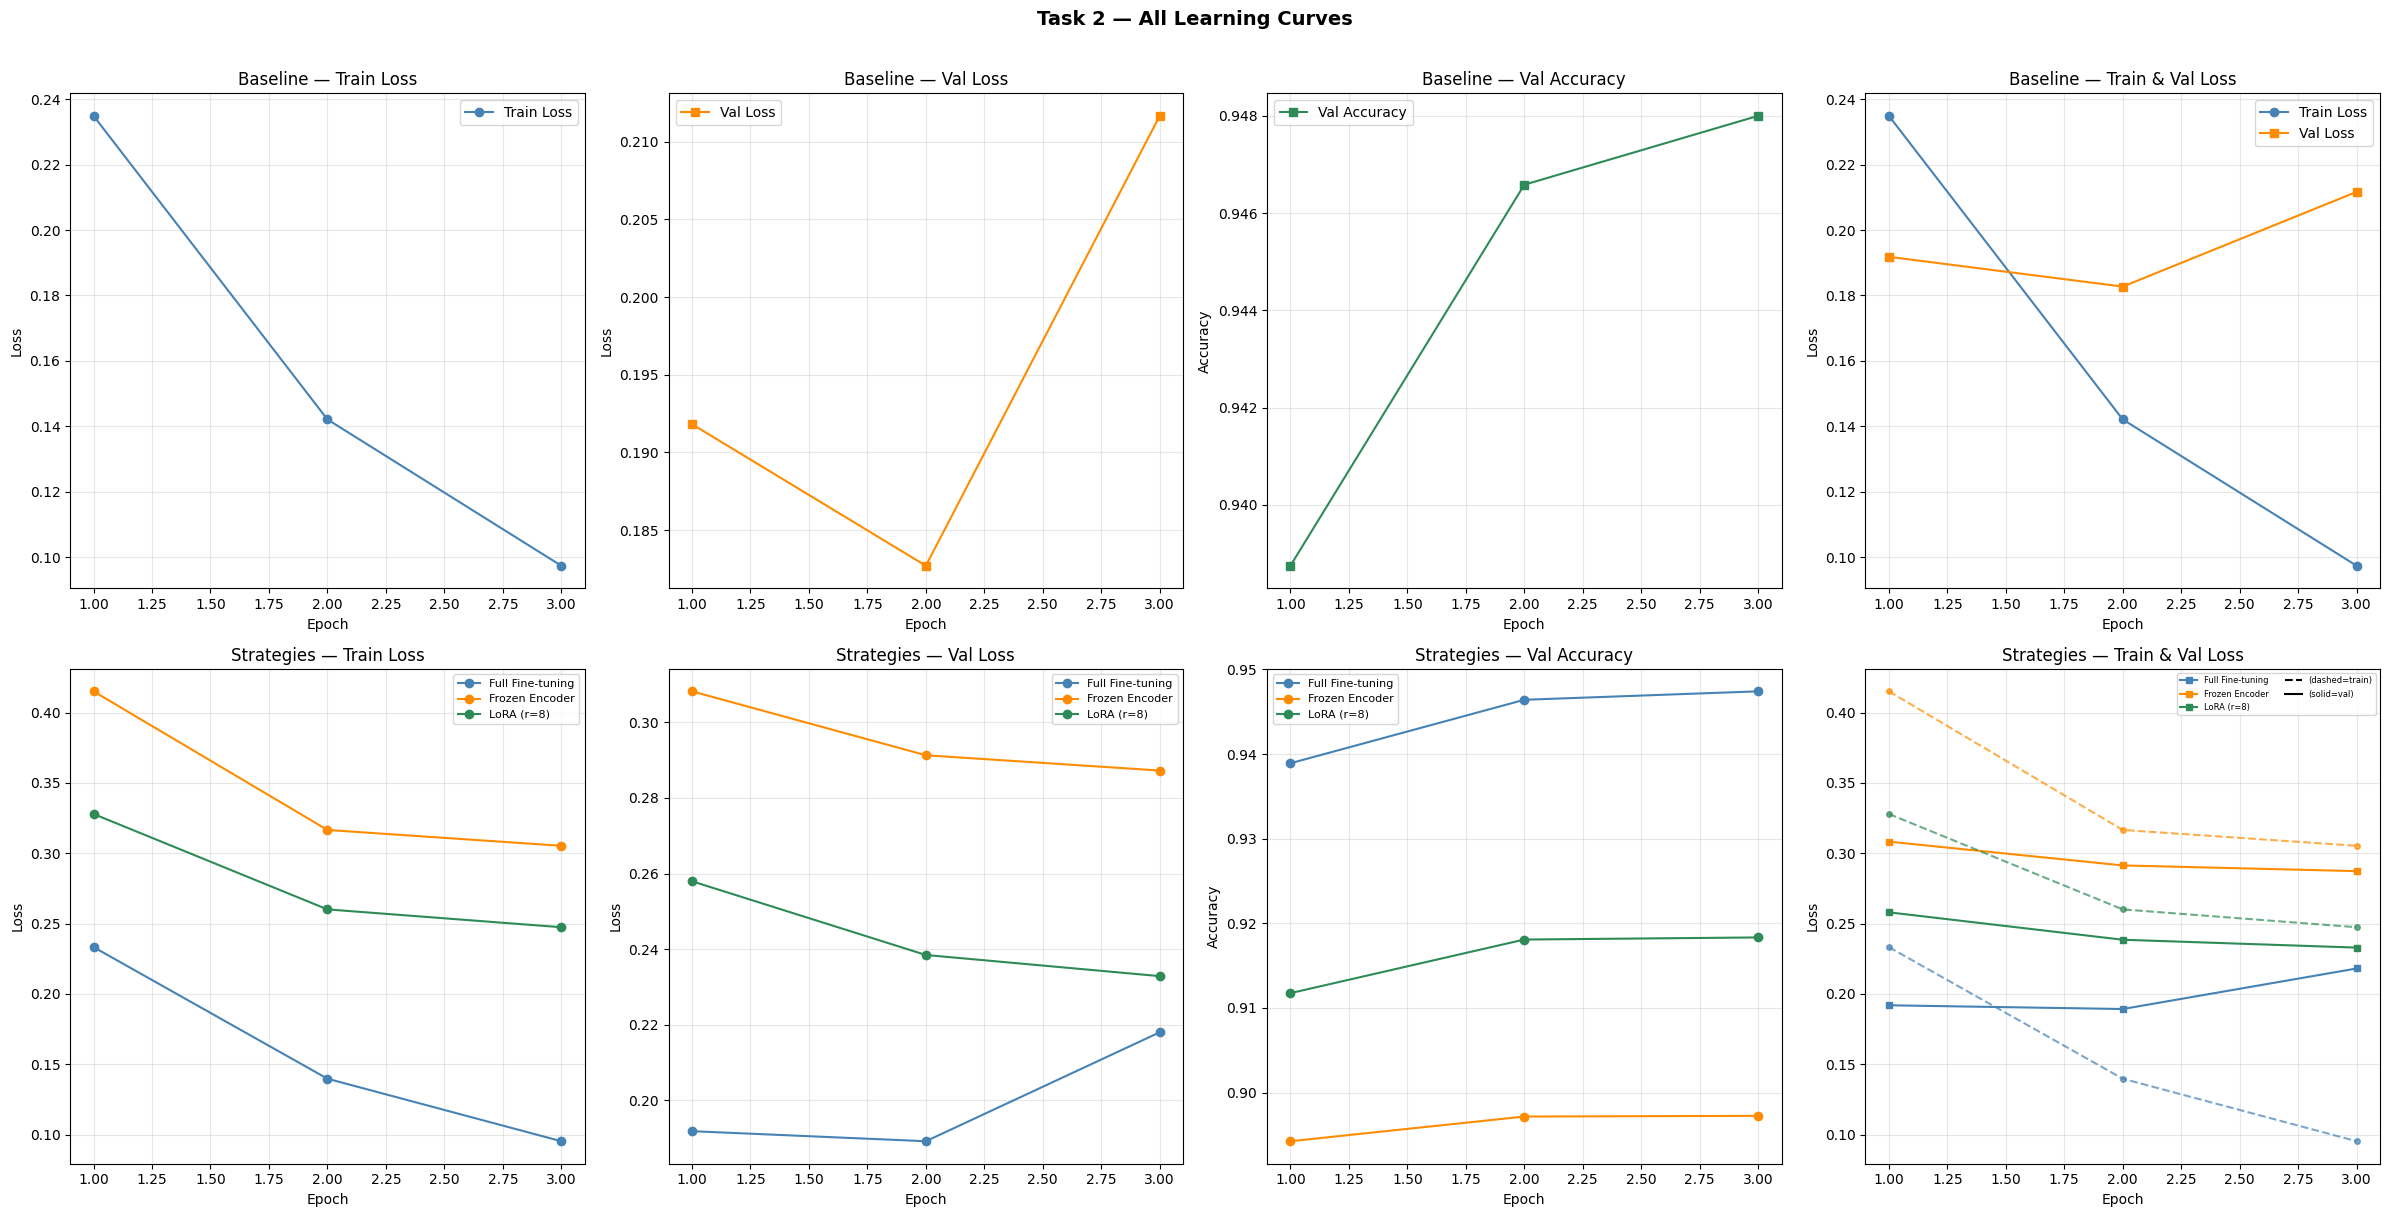

Saved: task2_all_learning_curves.png


In [64]:
#TASK 2: EXTENDED FINAL SUMMARY (tables + all learning curve plots)

SEP  = '=' * 78
SEP2 = '─' * 78

print(SEP)
print('  TASK 2 — EXTENDED FINAL SUMMARY')
print(SEP)
print(f'\nDataset   : AG News (4-class news classification)')
print(f'Split     : {len(dataset["train"]):,} train / '
      f'{len(dataset["validation"]):,} val / '
      f'{len(dataset["test"]):,} test')
print(f'Model     : distilbert-base-uncased')
print(f'Tokenizer : WordPiece subword  (L_max=128)')
print(f'Device    : Colab T4 GPU')

#BASELINE
print(f'\n{SEP2}')
print('  BASELINE  Full Fine-tuning  (lr=2e-5, AdamW, batch=16, 3 epochs, fp16)')
print(SEP2)
print(f'  Total params    : 66,956,548  (all trainable)')
print(f'  Time/epoch      : {full_ft_train_time/3:.0f}s  '
      f'(total: {full_ft_train_time:.0f}s)')
print(f'  Best val acc    : {max(val_acc):.4f}  (epoch {val_acc.index(max(val_acc))+1})')
print(f'  Final val acc   : {val_acc[-1]:.4f}')
baseline_f1 = float(f1_score(labels, preds, average='macro'))
print(f'  Test accuracy   : {test_results["eval_accuracy"]:.4f}')
print(f'  Test macro F1   : {baseline_f1:.4f}')

print(f'\n  {"Epoch":>5} {"Train Loss":>11} {"Val Loss":>10} '
      f'{"Val Acc":>9} {"Time(s)":>9}')
print(f'  {"-"*52}')
time_per_ep = full_ft_train_time / 3
for i, (tl, vl, va) in enumerate(zip(train_loss, val_loss, val_acc), 1):
    marker = ' [best]' if vl == min(val_loss) else ''
    print(f'  {i:5d} {tl:11.4f} {vl:10.4f} {va:9.4f} {time_per_ep:9.1f}{marker}')

#OING BEYOND 1: STRATEGY COMPARISON
print(f'\n{SEP2}')
print(f'  GOING BEYOND 1 — Training Strategy Comparison')
print(SEP2)
print(f'  {"Strategy":<22} {"Trainable":>12} {"Total":>12} '
      f'{"BestValAcc":>11} {"TestAcc":>9} {"MacroF1":>9} {"Time/ep":>9}')
print(f'  {"-"*78}')
for r in sorted(strategy_results, key=lambda x: -x['test_acc']):
    flag = ' <- best' if r['test_acc'] == max(x['test_acc'] for x in strategy_results) else ''
    print(f'  {r["name"]:<22} {r["trainable"]:>12,} {r["total_params"]:>12,} '
          f'{max(r["history"]["val_acc"]):>11.4f} '
          f'{r["test_acc"]:>9.4f} {r["test_f1"]:>9.4f} '
          f'{r["time_per_epoch"]:>8.0f}s{flag}')

print(f'\n  Per-epoch learning curves:')
print(f'  {"Strategy":<22} {"Epoch":>5} {"Train Loss":>11} '
      f'{"Val Loss":>10} {"Val Acc":>9} {"Time(s)":>9}')
print(f'  {"-"*70}')
for r in sorted(strategy_results, key=lambda x: -x['test_acc']):
    for i, (tl, vl, va) in enumerate(zip(
            r['history']['train_loss'],
            r['history']['val_loss'],
            r['history']['val_acc']), 1):
        marker = ' [best]' if vl == min(r['history']['val_loss']) else ''
        name_col = r['name'] if i == 1 else ''
        print(f'  {name_col:<22} {i:5d} {tl:11.4f} {vl:10.4f} '
              f'{va:9.4f} {r["time_per_epoch"]:9.0f}{marker}')
    print()

#GOING BEYOND 2: L_max ABLATION
print(f'\n{SEP2}')
print(f'  GOING BEYOND 2 — L_max Ablation  (1 epoch, full fine-tuning)')
print(SEP2)
print(f'  {"L_max":>6} {"AvgTok":>8} {"Trainable":>12} '
      f'{"TestAcc":>9} {"MacroF1":>9} {"Time/ep":>9} {"Speedup":>8}')
print(f'  {"-"*70}')
base_time = lmax_results[-1]['time_per_epoch']
for r in lmax_results:
    speedup = base_time / r['time_per_epoch']
    print(f'  {r["max_len"]:>6} {r["avg_tokens"]:>8.1f} '
          f'{r["trainable"]:>12,} '
          f'{r["test_acc"]:>9.4f} {r["test_f1"]:>9.4f} '
          f'{r["time_per_epoch"]:>9.1f} {speedup:>7.2f}x')

#OVERALL BEST
best_t2 = max(strategy_results, key=lambda x: x['test_acc'])
print(f'\n{SEP}')
print(f'  OVERALL BEST (Task 2): {best_t2["name"]}')
print(f'  Test acc = {best_t2["test_acc"]:.4f}  |  '
      f'Macro F1 = {best_t2["test_f1"]:.4f}  |  '
      f'Trainable = {best_t2["trainable"]:,}')
print(SEP)

# ═════════════════════════════════════════════════════════════════════════════
# ALL LEARNING CURVE PLOTS IN ONE FIGURE
# ═════════════════════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(24, 12))   # wider for 4 columns
fig.suptitle('Task 2 — All Learning Curves', fontsize=14, fontweight='bold', y=1.01)

ep_base = list(range(1, len(train_loss) + 1))

#Row 1: Baseline
ax1 = fig.add_subplot(2, 4, 1)
ax1.plot(ep_base, train_loss, 'o-', color='steelblue', label='Train Loss')
ax1.set_title('Baseline — Train Loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.grid(alpha=0.3); ax1.legend()

ax2 = fig.add_subplot(2, 4, 2)
ax2.plot(ep_base, val_loss, 's-', color='darkorange', label='Val Loss')
ax2.set_title('Baseline — Val Loss')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.grid(alpha=0.3); ax2.legend()

ax3 = fig.add_subplot(2, 4, 3)
ax3.plot(ep_base, val_acc, 's-', color='seagreen', label='Val Accuracy')
ax3.set_title('Baseline — Val Accuracy')
ax3.set_xlabel('Epoch'); ax3.set_ylabel('Accuracy')
ax3.grid(alpha=0.3); ax3.legend()

ax_extra1 = fig.add_subplot(2, 4, 4)   # ← NEW: combined train + val loss
ax_extra1.plot(ep_base, train_loss, 'o-', color='steelblue',  label='Train Loss')
ax_extra1.plot(ep_base, val_loss,   's-', color='darkorange', label='Val Loss')
ax_extra1.set_title('Baseline — Train & Val Loss')
ax_extra1.set_xlabel('Epoch'); ax_extra1.set_ylabel('Loss')
ax_extra1.grid(alpha=0.3); ax_extra1.legend()

#Row 2: Strategy comparison
colors_s = ['steelblue', 'darkorange', 'seagreen']

ax4 = fig.add_subplot(2, 4, 5)
ax5 = fig.add_subplot(2, 4, 6)
ax6 = fig.add_subplot(2, 4, 7)
ax_extra2 = fig.add_subplot(2, 4, 8)   # ← NEW: combined train + val loss

for r, c in zip(strategy_results, colors_s):
    ep = range(1, r['epochs'] + 1)
    ax4.plot(ep, r['history']['train_loss'], 'o-', label=r['name'], color=c)
    ax5.plot(ep, r['history']['val_loss'],   'o-', label=r['name'], color=c)
    ax6.plot(ep, r['history']['val_acc'],    'o-', label=r['name'], color=c)
    ax_extra2.plot(ep, r['history']['train_loss'], 'o--', markersize=4,
                   color=c, alpha=0.7)
    ax_extra2.plot(ep, r['history']['val_loss'],   's-',  markersize=4,
                   color=c, label=r['name'])

for ax, title, yl in zip(
    [ax4, ax5, ax6],
    ['Strategies — Train Loss',
     'Strategies — Val Loss',
     'Strategies — Val Accuracy'],
    ['Loss', 'Loss', 'Accuracy']):
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel(yl)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax_extra2.set_title('Strategies — Train & Val Loss')
ax_extra2.set_xlabel('Epoch'); ax_extra2.set_ylabel('Loss')
ax_extra2.legend(fontsize=7)
ax_extra2.grid(alpha=0.3)

# Add a note that dashed = train, solid = val
ax_extra2.plot([], [], 'k--', label='(dashed=train)')
ax_extra2.plot([], [], 'k-',  label='(solid=val)')
ax_extra2.legend(fontsize=6, ncol=2)

plt.tight_layout()
plt.savefig('task2_all_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: task2_all_learning_curves.png')